# EDA датасета Industrial Event Ranker

**Цель:** оценить состав, полноту, качество и временную структуру снимков инцидентов; проверить разметку P1–P4; изучить признаки, связанные с экспертным приоритетом; проверить, можно ли восстановить группы одновременно активных инцидентов для оценки ранжирования очереди.

**Единица наблюдения:** один снимок состояния инцидента (`incident_id`) на момент `snapshot_time`. Один инцидент может иметь несколько снимков.

**Целевая переменная:** `expert_priority` (P1 — критический, P2 — высокий, P3 — средний, P4 — низкий). `historical_priority` используется для аудита согласованности и как исторический baseline, но не как признак модели.

**Особенность текущей версии схемы:** кроме исходного контекста инцидента, CSV включает `queue_refresh_time`, `queue_id`, `dispatcher_session_id` и `incident_end_time`. Эти поля используются для проверки актуальности снимка и группировки событий в очереди; идентификаторы не включаются в матрицу признаков.

## Запуск

1. Убедитесь, что доступен `data/incidents_raw.csv`.
2. При необходимости измените `CSV_PATH` в конфигурационной ячейке.
3. Выполните ноутбук сверху вниз.
4. Таблицы и графики дополнительно сохраняются в `reports/eda/` относительно корня проекта.

## 1. Импорт библиотек и настройки

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import cohen_kappa_score, confusion_matrix

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
PRIORITY_ORDER = ["P1", "P2", "P3", "P4"]
PRIORITY_TO_GRADE = {"P1": 4, "P2": 3, "P3": 2, "P4": 1}

## 2. Загрузка данных

In [2]:
# Укажите путь явно, если CSV лежит в нестандартном месте.
CSV_PATH = Path(r"..\data\incidents_raw_1.csv")

if CSV_PATH is not None:
    CSV_PATH = Path(CSV_PATH).expanduser()
    if not CSV_PATH.is_absolute():
        CSV_PATH = (Path.cwd() / CSV_PATH).resolve()
else:
    excluded = {".git", ".venv", "venv", "__pycache__", "node_modules", ".ipynb_checkpoints"}
    roots = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    candidates = set()
    for root in roots:
        if root.exists():
            for p in root.rglob("incidents_raw.csv"):
                if not any(part in excluded for part in p.parts):
                    candidates.add(p.resolve())
    if len(candidates) == 1:
        CSV_PATH = next(iter(candidates))
    elif not candidates:
        raise FileNotFoundError(
            "incidents_raw.csv не найден. Укажите CSV_PATH в этой ячейке."
        )
    else:
        preferred = [p for p in candidates if "data" in p.parts and "raw" in p.parts]
        if len(preferred) == 1:
            CSV_PATH = preferred[0]
        else:
            raise RuntimeError(
                "Найдено несколько incidents_raw.csv. Укажите CSV_PATH явно:\n" +
                "\n".join(map(str, sorted(candidates)))
            )

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()),
    Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports" / "eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(CSV_PATH)
df = raw.copy()

print(f"Файл: {CSV_PATH}")
print(f"Размер: {len(df):,} строк × {df.shape[1]} столбцов")
print(f"Память DataFrame: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MiB")
print(f"Папка отчётов: {OUTPUT_DIR}")
display(df.head())

Файл: F:\itmo\courses\industrial-event-ranker\data\incidents_raw_1.csv
Размер: 14,384 строк × 35 столбцов
Память DataFrame: 17.58 MiB
Папка отчётов: f:\itmo\courses\industrial-event-ranker\reports\eda


,snapshot_id,incident_id,snapshot_time,queue_refresh_time,queue_id,dispatcher_session_id,incident_start_time,incident_end_time,event_type,object_type,zone_id,zone_type,zone_hazard_level,access_mode,historical_outcome,consequence_severity,expert_priority,historical_priority,x,y,speed_mps,heading_deg,acceleration,trajectory_change,distance_to_zone_border,nearest_object_type,nearest_object_distance,secondary_object_distance,event_source,previous_incidents_count,time_of_day,day_of_week,incident_duration_sec,n_observations,has_clock_skew
0,INC_000000_S00,INC_000000,2025-01-01 00:05:18.149581629,2025-01-01 00:05:00,Q_20250101_0005,SHIFT_0000,2025-01-01 00:02:49.526725193,2025-01-01 00:47:49.526725193,unusual_trajectory,forklift,Z_058,loading_dock,low,open,NaN,NaN,NaN,P4,-11.656397,5.673142,1.951709,186.911496,0.172182,NaN,24.681065,forklift,14.331580,NaN,manual,0.0,0,2,148.622856,1,False
1,INC_000000_S01,INC_000000,2025-01-01 00:22:04.010638593,2025-01-01 00:20:00,Q_20250101_0020,SHIFT_0000,2025-01-01 00:02:49.526725193,2025-01-01 00:47:49.526725193,unusual_trajectory,forklift,Z_058,loading_dock,low,NaN,NaN,NaN,NaN,P4,-41.077488,0.868610,1.017563,156.527881,0.002142,0.232747,16.603926,tractor,NaN,NaN,camera,1.0,0,2,1154.483913,2,False
2,INC_000000_S02,INC_000000,2025-01-01 00:28:31.693132888,2025-01-01 00:25:00,Q_20250101_0025,SHIFT_0000,2025-01-01 00:02:49.526725193,2025-01-01 00:47:49.526725193,unusual_trajectory,Forklift,Z_058,loading_dock,low,open,closed,NaN,NaN,P4,-4.149652,-38.132740,0.965696,63.181885,-0.047356,NaN,7.832748,tractor,20.043096,NaN,lidar,0.0,0,2,1542.166408,3,False
3,INC_000001_S00,INC_000001,2025-01-01 00:29:48.005586770,2025-01-01 00:25:00,Q_20250101_0025,SHIFT_0000,2025-01-01 00:26:47.996797216,2025-01-01 00:48:28.595482868,restricted_zone_breach,reach_truck,Z_027,restricted,medium,authorized_only,NaN,NaN,P2,P2,70.582898,-57.106751,5.063389,265.111023,1.743978,0.792818,6.430365,forklift,5.417313,NaN,rfid,2.0,0,2,180.008790,1,False
4,INC_000001_S01,INC_000001,2025-01-01 00:30:24.540171048,2025-01-01 00:30:00,Q_20250101_0030,SHIFT_0000,2025-01-01 00:26:47.996797216,2025-01-01 00:48:28.595482868,restricted_zone_breach,reach_truck,Z_027,restricted,medium,authorized_only,resolved,NaN,P2,P2,-4.433944,125.597206,5.906071,333.350023,0.976200,0.413712,1.465406,pedestrian,9.984653,NaN,camera,3.0,0,2,216.543374,2,False


## 3. Схема, объём и полнота данных

Структура содержит идентификаторы снимка, инцидента и очереди; временные метки; контекст события и объекта; признаки зоны и движения; исторические поля и две метки приоритета. Объём строки CSV — это объём снимков, поэтому самостоятельной единицей оценки статистической независимости остаётся `incident_id`.

In [3]:
expected_columns = [
    "snapshot_id", "incident_id", "snapshot_time", "queue_refresh_time", "queue_id",
    "dispatcher_session_id", "incident_start_time", "incident_end_time", "event_type",
    "object_type", "zone_id", "zone_type", "zone_hazard_level", "access_mode",
    "historical_outcome", "consequence_severity", "expert_priority", "historical_priority",
    "x", "y", "speed_mps", "heading_deg", "acceleration", "trajectory_change",
    "distance_to_zone_border", "nearest_object_type", "nearest_object_distance",
    "secondary_object_distance", "event_source", "previous_incidents_count",
    "time_of_day", "day_of_week", "incident_duration_sec", "n_observations", "has_clock_skew"
]
missing_columns = sorted(set(expected_columns) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(expected_columns))

schema_report = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "non_null": [int(df[c].notna().sum()) for c in df.columns],
    "missing": [int(df[c].isna().sum()) for c in df.columns],
    "missing_share": [float(df[c].isna().mean()) for c in df.columns],
    "n_unique": [int(df[c].nunique(dropna=True)) for c in df.columns],
})
print("Отсутствующие поля схемы:", missing_columns or "нет")
print("Дополнительные поля:", extra_columns or "нет")
print("Уникальных incident_id:", df["incident_id"].nunique(dropna=True))
print("Уникальных snapshot_id:", df["snapshot_id"].nunique(dropna=True))
display(schema_report.sort_values("missing_share", ascending=False).style.format({"missing_share": "{:.1%}"}))
schema_report.to_csv(OUTPUT_DIR / "schema_report.csv", index=False)

Отсутствующие поля схемы: нет
Дополнительные поля: нет
Уникальных incident_id: 6286
Уникальных snapshot_id: 14105


,column,dtype,non_null,missing,missing_share,n_unique
27,secondary_object_distance,float64,32,14352,99.8%,30
15,consequence_severity,str,134,14250,99.1%,4
14,historical_outcome,str,1706,12678,88.1%,4
16,expert_priority,str,9563,4821,33.5%,4
22,acceleration,float64,10716,3668,25.5%,10417
23,trajectory_change,float64,11466,2918,20.3%,10771
29,previous_incidents_count,float64,12263,2121,14.7%,9
26,nearest_object_distance,float64,12952,1432,10.0%,12464
17,historical_priority,str,13186,1198,8.3%,4
13,access_mode,str,13253,1131,7.9%,3


In [4]:
display(Markdown(
    f"**Вывод по объёму и схеме.** "
    f"В текущей выгрузке **{len(df):,}** строк и **{df.shape[1]}** поля; "
    f"они соответствуют схеме с дополнительными полями для контекста "
    f"очереди и окончания инцидента. "
    f"В данных **{df['incident_id'].nunique():,}** уникальных `incident_id` и "
    f"**{df['snapshot_id'].nunique():,}** уникальных `snapshot_id`.\n\n"
    f"`zone_hazard_level` "
    f"({'/'.join(sorted(df['zone_hazard_level'].dropna().astype(str).unique()))}) "
    f"и `consequence_severity` являются категориальными полями "
    f"(уровни опасности зоны и уровни последствий соответственно), "
    f"а не числовыми величинами."
))

**Вывод по объёму и схеме.** В текущей выгрузке **14,384** строк и **35** поля; они соответствуют схеме с дополнительными полями для контекста очереди и окончания инцидента. В данных **6,286** уникальных `incident_id` и **14,105** уникальных `snapshot_id`.

`zone_hazard_level` (high/low/medium) и `consequence_severity` являются категориальными полями (уровни опасности зоны и уровни последствий соответственно), а не числовыми величинами.

**Среднее число строк на инцидент больше единицы**, поэтому все последующие оценки и разбиения учитывают группировку по incident_id

## 4. Типы и временные поля

In [5]:
datetime_columns = [c for c in [
    "snapshot_time", "queue_refresh_time", "incident_start_time", "incident_end_time"
] if c in df.columns]
for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

numeric_columns = [
    "x", "y", "speed_mps", "heading_deg", "acceleration", "trajectory_change",
    "distance_to_zone_border", "nearest_object_distance", "secondary_object_distance",
    "previous_incidents_count", "incident_duration_sec", "n_observations",
    "time_of_day", "day_of_week"
]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

def normalize_priority(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().upper().replace(" ", "")
    m = re.fullmatch(r"P?([1-4])", s)
    return f"P{m.group(1)}" if m else s

df["expert_priority_norm"] = df["expert_priority"].map(normalize_priority)
df["historical_priority_norm"] = df["historical_priority"].map(normalize_priority)
valid_label_mask = df["expert_priority_norm"].isin(PRIORITY_ORDER)
labeled = df.loc[valid_label_mask].copy()

profile = pd.Series({
    "rows_snapshots": len(df),
    "columns": df.shape[1] - 2,  # не считаем две технические нормализованные колонки как исходные поля
    "unique_incidents": df["incident_id"].nunique(dropna=True),
    "unique_snapshots": df["snapshot_id"].nunique(dropna=True),
    "labeled_rows": int(valid_label_mask.sum()),
    "label_coverage": float(valid_label_mask.mean()),
    "time_min_snapshot": df["snapshot_time"].min(),
    "time_max_snapshot": df["snapshot_time"].max(),
    "unique_snapshot_days": df["snapshot_time"].dt.floor("D").nunique(),
}, name="value")
display(profile.to_frame())
profile.to_csv(OUTPUT_DIR / "dataset_profile.csv")

,value
rows_snapshots,14384
columns,35
unique_incidents,6286
unique_snapshots,14105
labeled_rows,9563
label_coverage,0.664836
time_min_snapshot,2025-01-01 00:05:18.149581629+00:00
time_max_snapshot,2025-06-18 20:49:43.773103666+00:00
unique_snapshot_days,155


## 5. Пропуски и механизм их появления

,missing_count,missing_share,available_count
secondary_object_distance,14352,99.78%,32
consequence_severity,14250,99.07%,134
historical_outcome,12678,88.14%,1706
expert_priority,4821,33.52%,9563
expert_priority_norm,4821,33.52%,9563
acceleration,3668,25.50%,10716
trajectory_change,2918,20.29%,11466
previous_incidents_count,2121,14.75%,12263
nearest_object_distance,1432,9.96%,12952
historical_priority,1198,8.33%,13186


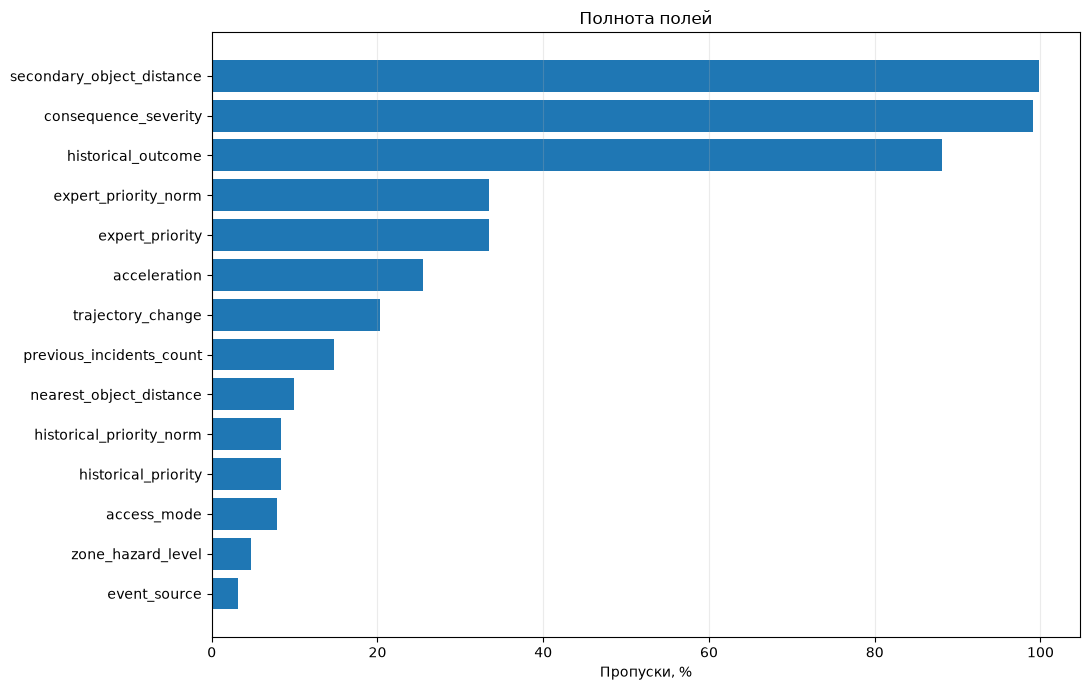

,acceleration,trajectory_change,previous_incidents_count,nearest_object_distance,access_mode,zone_hazard_level,event_source
_priority,,,,,,,
P1,27.3%,21.9%,14.9%,11.4%,7.4%,5.8%,2.6%
P2,24.3%,20.7%,15.8%,9.8%,8.5%,4.8%,3.4%
P3,26.3%,20.0%,15.3%,9.8%,8.0%,4.7%,2.9%
P4,24.3%,20.4%,14.1%,9.8%,7.8%,4.8%,3.4%
Без метки,26.1%,19.8%,14.6%,10.0%,7.7%,4.6%,3.1%


In [6]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_share": df.isna().mean(),
    "available_count": df.notna().sum(),
}).sort_values("missing_share", ascending=False)
display(missing_report.style.format({"missing_share": "{:.2%}"}))
missing_report.to_csv(OUTPUT_DIR / "missing_values.csv")

fig, ax = plt.subplots(figsize=(11, 7))
plot_missing = missing_report[missing_report["missing_count"] > 0].sort_values("missing_share")
ax.barh(plot_missing.index, plot_missing["missing_share"] * 100)
ax.set_xlabel("Пропуски, %")
ax.set_title("Полнота полей")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "missingness_by_column.png", dpi=160, bbox_inches="tight")
plt.show()

missing_by_priority = df.assign(_priority=df["expert_priority_norm"].fillna("Без метки")).groupby("_priority")[
    [c for c in ["acceleration", "trajectory_change", "previous_incidents_count", "nearest_object_distance", "access_mode", "zone_hazard_level", "event_source"] if c in df]
].apply(lambda x: x.isna().mean())
display(missing_by_priority.style.format("{:.1%}"))
missing_by_priority.to_csv(OUTPUT_DIR / "missingness_by_priority.csv")

**Фактический результат.** Наиболее разрежены `secondary_object_distance` (99,8% пропусков), `consequence_severity` (99%) и `historical_outcome` (88,1%). Для обучения текущей модели эти поля исключаются: первые два практически не имеют покрытия, а outcome/severity относятся к ретроспективной информации. Их можно оставить только для последующей аналитики качества разметки.

`acceleration` отсутствует в 25,5% строк, `trajectory_change` — в 20.3%, `previous_incidents_count` — в 14,7%, `nearest_object_distance` — в 9.9%. Доля пропусков этих признаков по классам близка, поэтому в MVP разумно проверять использование этих полей вместе с отдельными флагами пропуска. Удаление строк по этим полям резко сократило бы выборку.

## 6. Целевая переменная и дисбаланс классов

Корректные метки P1–P4: 9,563 / 14,384 (66.5%)


,rows,share_labeled,share_all_rows
expert_priority_norm,,,
P1,1097,11.5%,7.6%
P2,1906,19.9%,13.3%
P3,2459,25.7%,17.1%
P4,4101,42.9%,28.5%


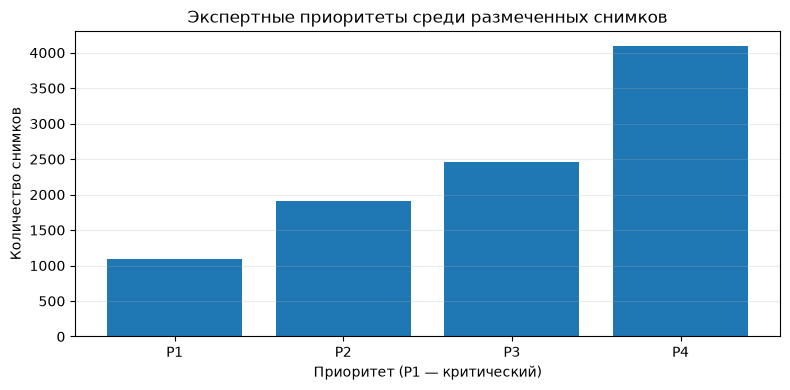

In [7]:
class_counts = labeled["expert_priority_norm"].value_counts().reindex(PRIORITY_ORDER, fill_value=0)
class_report = pd.DataFrame({
    "rows": class_counts,
    "share_labeled": class_counts / max(len(labeled), 1),
    "share_all_rows": class_counts / max(len(df), 1),
})
print(f"Корректные метки P1–P4: {len(labeled):,} / {len(df):,} ({len(labeled)/len(df):.1%})")
display(class_report.style.format({"share_labeled": "{:.1%}", "share_all_rows": "{:.1%}"}))
class_report.to_csv(OUTPUT_DIR / "priority_distribution.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_report.index, class_report["rows"])
ax.set_title("Экспертные приоритеты среди размеченных снимков")
ax.set_xlabel("Приоритет (P1 — критический)")
ax.set_ylabel("Количество снимков")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "expert_priority_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Вывод по разметке.** Экспертная метка заполнена для 9,563 строк (66.5%). Среди размеченных снимков распределение составляет P1 — 11,5%, P2 — 19,9%, P3 — 25.7%, P4 — 42.9%. Таким образом, как и ожидалось классы не несбалансированы: P4 встречается примерно в 3.8 раза чаще P1.

Accuracy не будет достаточной метрикой. Нужны `macro F1`, метрики по каждому классу и отдельная полнота P1. При обучении сравнивнить обычную и взвешенную функцию потерь.

Корректные исторические метки P1–P4: 13,186 / 14,384 (91.7%)


,rows,share_labeled,share_all_rows
historical_priority_norm,,,
P1,1383,10.5%,9.6%
P2,2443,18.5%,17.0%
P3,4327,32.8%,30.1%
P4,5033,38.2%,35.0%


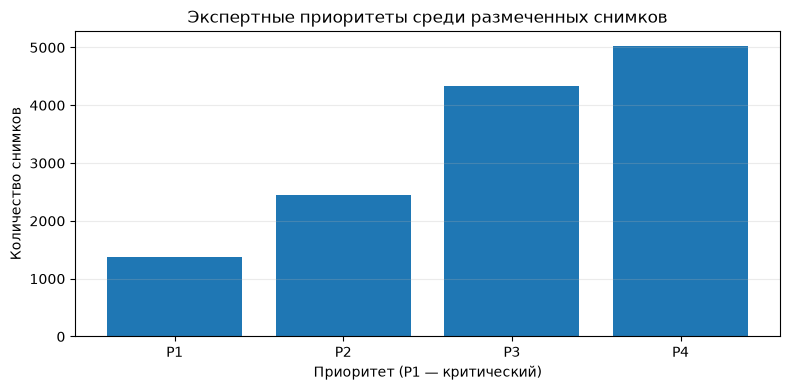

In [8]:
valid_label_mask = df["historical_priority_norm"].isin(PRIORITY_ORDER)
historical_labeled = df.loc[valid_label_mask].copy()

class_counts = historical_labeled["historical_priority_norm"].value_counts().reindex(PRIORITY_ORDER, fill_value=0)
class_report = pd.DataFrame({
    "rows": class_counts,
    "share_labeled": class_counts / max(len(historical_labeled), 1),
    "share_all_rows": class_counts / max(len(df), 1),
})
print(f"Корректные исторические метки P1–P4: {len(historical_labeled):,} / {len(df):,} ({len(historical_labeled)/len(df):.1%})")
display(class_report.style.format({"share_labeled": "{:.1%}", "share_all_rows": "{:.1%}"}))
class_report.to_csv(OUTPUT_DIR / "historical_priority_distribution.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_report.index, class_report["rows"])
ax.set_title("Экспертные приоритеты среди размеченных снимков")
ax.set_xlabel("Приоритет (P1 — критический)")
ax.set_ylabel("Количество снимков")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "historical_priority_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Полнота исторической разметки.** `historical_priority` доступен почти для всех инцидентов: **91.7% строк** (13 186 из 14 384) содержат корректную метку P1–P4. Это существенно выше, чем у `expert_priority`, где корректная метка есть только у **66.5% строк** (9 563 из 14 384). Такая асимметрия ожидаема: исторический приоритет — это решение, которое диспетчер **обязан** зафиксировать в процессе работы, тогда как экспертная переразметка выполняется **выборочно** и стратифицированно, покрывая лишь часть выборки.

Среди строк с корректной исторической меткой распределение смещено к средним и низким приоритетам: P3 и P4 доминируют, P1 остаётся редким классом (~10%). Это соответствует бизнес-описанию и подтверждает необходимость работы с дисбалансом классов.

Нужно измерить согласованность historical_priority × expert_priority на подвыборке, где есть обе метки. Ожидаемо согласие ~85–90% с систематическим сдвигом к P3 (диспетчер склонен ставить средний приоритет судя по графикам).

## 7. Повторные снимки и согласованность метки внутри инцидента

Число снимков на инцидент:


,n_snapshots
count,6286.000000
mean,2.288260
std,1.235105
min,1.000000
50%,2.000000
75%,3.000000
90%,4.000000
95%,5.000000
99%,5.000000
max,7.000000


,incident_count
unique_incidents,6286
incidents_without_expert_label,2047
incidents_with_one_expert_label,4239
incidents_with_conflicting_expert_labels,0


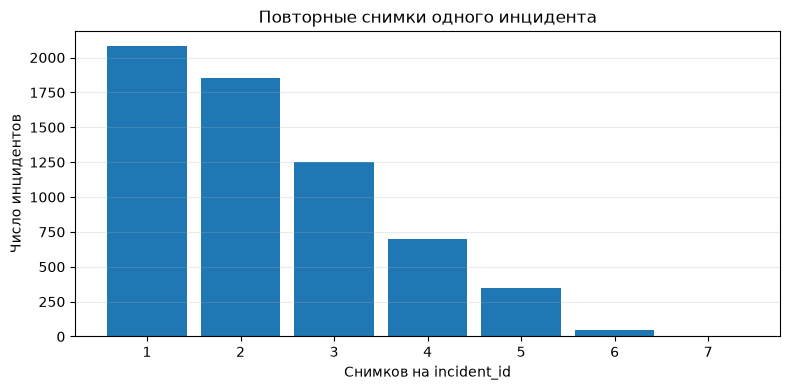

,unique_labeled_incidents
expert_priority,
P1,475
P2,840
P3,1094
P4,1830


In [9]:
incident_sizes = df.groupby("incident_id").size().rename("n_snapshots")
incident_label_nunique = labeled.groupby("incident_id")["expert_priority_norm"].nunique()
all_incident_label_nunique = df.groupby("incident_id")["expert_priority_norm"].nunique(dropna=True)
incident_label_counts = pd.Series({
    "unique_incidents": df["incident_id"].nunique(),
    "incidents_without_expert_label": int((all_incident_label_nunique == 0).sum()),
    "incidents_with_one_expert_label": int((all_incident_label_nunique == 1).sum()),
    "incidents_with_conflicting_expert_labels": int((all_incident_label_nunique > 1).sum()),
}, name="incident_count")
print("Число снимков на инцидент:")
display(incident_sizes.describe(percentiles=[.5, .75, .9, .95, .99]).to_frame())
display(incident_label_counts.to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(incident_sizes, bins=range(1, int(incident_sizes.max()) + 2), align="left", rwidth=0.85)
ax.set_xticks(range(1, int(incident_sizes.max()) + 1))
ax.set_xlabel("Снимков на incident_id")
ax.set_ylabel("Число инцидентов")
ax.set_title("Повторные снимки одного инцидента")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "snapshots_per_incident.png", dpi=160, bbox_inches="tight")
plt.show()

incident_level = (
    labeled.sort_values("snapshot_time")
    .groupby("incident_id", as_index=False)
    .agg(expert_priority=("expert_priority_norm", "first"),
         incident_start_time=("incident_start_time", "min"))
)
incident_class_counts = incident_level["expert_priority"].value_counts().reindex(PRIORITY_ORDER, fill_value=0)
display(incident_class_counts.rename("unique_labeled_incidents").to_frame())
incident_class_counts.rename("unique_labeled_incidents").to_csv(OUTPUT_DIR / "priority_by_unique_incident.csv")

**Вывод по гранулярности.** На один `incident_id` приходится в среднем 2,28 снимка; медиана — 2, 95-й процентиль — 5, максимум — 7. Для 2047 инцидентов экспертная метка отсутствует, у 4239 инцидента присутствует ровно одна уникальная метка, конфликтующих инцидентов не обнаружено. Это подтверждает возможность использовать `incident_id` как группу для разбиения и показывает, что экспертная метка в текущей выгрузке постоянна внутри инцидента.

На уровне уникальных размеченных инцидентов: **P1 — 475, P2 — 840, P3 — 1094, P4 — 1830**. Эти числа важнее количества снимков при оценке независимого объёма обучающей выборки.

## 8. Дубликаты и повторяющиеся ключи

In [10]:
exact_duplicate_excess = int(df.duplicated().sum())
snapshot_id_duplicate_rows = int(df.duplicated("snapshot_id", keep=False).sum())
key_cols = ["incident_id", "snapshot_time"]
key_dup = df[df.duplicated(key_cols, keep=False)].copy()
key_group_n = key_dup.groupby(key_cols, dropna=False).ngroups if not key_dup.empty else 0

non_key_columns = [c for c in df.columns if c not in key_cols]
conflict_by_key = (
    key_dup.groupby(key_cols, dropna=False)[non_key_columns]
    .nunique(dropna=False).gt(1).any(axis=1)
) if not key_dup.empty else pd.Series(dtype=bool)
conflicting_key_groups = int(conflict_by_key.sum())
identical_key_groups = int((~conflict_by_key).sum()) if len(conflict_by_key) else 0

# Отдельно проверяем, какие поля реально отличаются у повторяющихся ключей.
diff_fields = {}
if not key_dup.empty:
    per_key_nunique = key_dup.groupby(key_cols, dropna=False)[non_key_columns].nunique(dropna=False)
    diff_fields = per_key_nunique.gt(1).sum().loc[lambda s: s > 0].sort_values(ascending=False).to_dict()

duplicate_report = pd.Series({
    "exact_duplicate_excess_rows": exact_duplicate_excess,
    "exact_duplicate_share": exact_duplicate_excess / len(df),
    "rows_with_repeated_snapshot_id": snapshot_id_duplicate_rows,
    "rows_with_repeated_incident_snapshot_key": len(key_dup),
    "repeated_incident_snapshot_key_groups": key_group_n,
    "conflicting_key_groups": conflicting_key_groups,
    "non_conflicting_key_groups": identical_key_groups,
}, name="value")
display(duplicate_report.to_frame())
display(pd.Series(diff_fields, name="conflicting_key_groups_by_column").to_frame())
duplicate_report.to_csv(OUTPUT_DIR / "duplicate_audit.csv")

,value
exact_duplicate_excess_rows,279.000000
exact_duplicate_share,0.019397
rows_with_repeated_snapshot_id,558.000000
rows_with_repeated_incident_snapshot_key,834.000000
repeated_incident_snapshot_key_groups,416.000000
conflicting_key_groups,139.000000
non_conflicting_key_groups,277.000000


,conflicting_key_groups_by_column
snapshot_id,139
x,139
y,139
speed_mps,139
distance_to_zone_border,139


**Вывод по дубликатам.** Найдено 279 дополнительных точных повторения строк (1,9% объёма). Повторяющиеся `snapshot_id` встречаются в 558 парах. Ключ `(incident_id, snapshot_time)` повторяется в 416 группах (834 строк): 251 группа не имеет различий в содержательных полях, а в 139 группах отличаются `x`, `y`, `speed_mps` и `distance_to_zone_border` (а также технический `snapshot_id`).

Следовательно, `drop_duplicates()` удалит точные повторы, но не решит все коллизии ключа. 139 конфликтующих групп нужно разрешить по версии/источнику или правилу формирования дубля. При этом ельзя произвольно выбирать одну строку. Аудит необходимо провести до разбиения на выборки.

## 9. Категориальные признаки и нормализация

In [11]:
def normalize_category(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower()
    s = re.sub(r"[\s\-/]+", "_", s)
    s = re.sub(r"[^\wа-яё_]+", "", s, flags=re.IGNORECASE)
    return re.sub(r"_+", "_", s).strip("_")

category_columns = [c for c in [
    "event_type", "object_type", "zone_type", "zone_hazard_level", "access_mode",
    "nearest_object_type", "event_source", "historical_outcome", "consequence_severity"
] if c in df.columns]
category_rows = []
for col in category_columns:
    norm = df[col].map(normalize_category)
    category_rows.append({
        "column": col,
        "unique_raw": df[col].nunique(dropna=True),
        "unique_after_case_space_normalization": norm.nunique(dropna=True),
        "top_raw_values": "; ".join(map(str, df[col].value_counts(dropna=True).head(8).index)),
    })
category_audit = pd.DataFrame(category_rows).set_index("column")
display(category_audit)
category_audit.to_csv(OUTPUT_DIR / "category_audit.csv")

# Справочник кандидатов на семантическое объединение.
semantic_alias_candidates = pd.DataFrame([
    ["object_type", "rt", "reach_truck"],
    ["object_type", "ped", "pedestrian"],
    ["zone_type", "ped_path", "pedestrian_path"],
    ["zone_type", "restricted_zone", "restricted"],
    ["zone_type", "maintenance_area", "maintenance"],
], columns=["column", "observed_normalized_value", "candidate_canonical_value"])
display(semantic_alias_candidates)
semantic_alias_candidates.to_csv(OUTPUT_DIR / "semantic_alias_candidates.csv", index=False)

,unique_raw,unique_after_case_space_normalization,top_raw_values
column,,,
event_type,12,6,zone_behavior_deviation; unusual_trajectory; pedestrian_zone_vehicle; zone_intrusion; restricted_zone_breach; pedest...
object_type,15,6,forklift; reach_truck; pedestrian; tractor; forklift ; Reach_Truck; Forklift; FORKLIFT
zone_type,21,9,storage; loading_dock; pedestrian_path; maintenance; intersection; restricted; loading dock; Loading_Dock
zone_hazard_level,3,3,low; medium; high
access_mode,3,3,open; restricted; authorized_only
nearest_object_type,4,4,reach_truck; forklift; tractor; pedestrian
event_source,5,5,camera; lidar; rfid; combined; manual
historical_outcome,4,4,closed; resolved; escalated; unresolved
consequence_severity,4,4,none; minor; moderate; severe


,column,observed_normalized_value,candidate_canonical_value
0,object_type,rt,reach_truck
1,object_type,ped,pedestrian
2,zone_type,ped_path,pedestrian_path
3,zone_type,restricted_zone,restricted
4,zone_type,maintenance_area,maintenance


**Вывод по категориям.** Простая нормализация регистра, пробелов и разделителей сокращает число вариантов `zone_type` с 21 до 9, `event_type` с 12 до 6 и `object_type` с 15 до 6. Для оставшихся нескольких вариантов `rt`, `ped`, `ped_path`, `restricted_zone` и `maintenance_area` было уточнено, что они имеют семантическое сходство и также следует их объединить.

## 10. Числовые признаки, диапазоны и экстремальные значения

,count,mean,std,min,1%,5%,50%,95%,99%,max
x,14384.0,0.128455,49.826813,-179.888403,-117.433273,-82.239738,0.380599,81.780944,115.407349,199.627906
y,14384.0,-0.464093,49.573170,-179.083087,-114.071153,-80.995513,-0.815342,82.312196,116.406829,249.663806
speed_mps,14384.0,5.563748,9.566231,0.099948,0.106323,0.897235,4.360448,11.487864,15.267253,195.805355
heading_deg,14384.0,179.982230,104.238589,0.013003,3.545268,17.809191,180.205870,342.400772,356.521886,359.935098
acceleration,10716.0,0.666444,1.388145,-24.966143,-0.585729,-0.151292,0.389850,2.433530,3.517929,24.341522
trajectory_change,11466.0,0.382667,0.245807,0.000000,0.000000,0.038507,0.348524,0.827075,0.968532,1.000000
distance_to_zone_border,14384.0,8.949342,10.177023,-118.096159,-4.762225,-2.850369,7.764463,25.497031,31.597352,46.315605
nearest_object_distance,12952.0,11.055340,8.696817,-19.652498,0.100000,1.260423,8.618839,28.221413,34.880554,44.624234
secondary_object_distance,32.0,14.665551,8.419341,2.351236,2.563181,3.034930,17.456024,25.727134,28.884383,29.331120
previous_incidents_count,12263.0,1.501590,1.230018,0.000000,0.000000,0.000000,1.000000,4.000000,5.000000,8.000000


,column,check,count,share,interpretation
0,speed_mps,> 50 m/s,62,0.43%,Экстремальная скорость; требуется проверка единиц и сценария.
1,speed_mps,< 0,0,0.00%,Отрицательная скорость.
2,heading_deg,"outside [0, 360]",0,0.00%,Выход за стандартный диапазон направления.
3,distance_to_zone_border,< 0,2550,17.73%,Отрицательное значение может быть знаковым расстоянием; нужна спецификация поля.
4,nearest_object_distance,< 0,55,0.38%,Отрицательная дистанция требует проверки семантики и качества измерения.
5,acceleration,absolute value > 10 m/s²,37,0.26%,Экстремальные ускорения; проверить сенсор и единицы измерения.


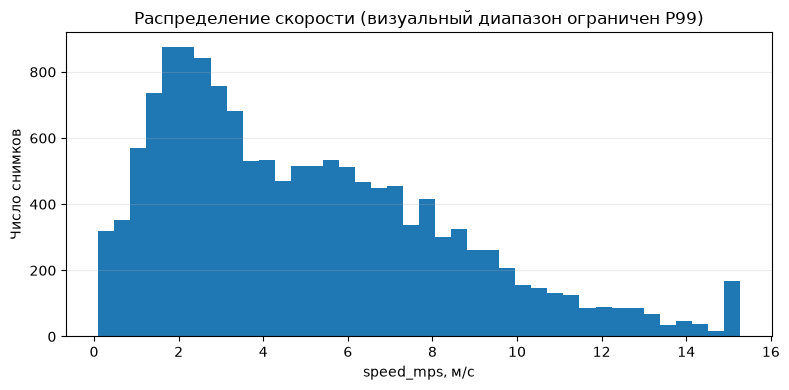

In [12]:
num_for_profile = [c for c in numeric_columns if c in df.columns]
numeric_profile = df[num_for_profile].describe(percentiles=[.01, .05, .5, .95, .99]).T
display(numeric_profile)
numeric_profile.to_csv(OUTPUT_DIR / "numeric_profile.csv")

range_rows = []
def add_range_row(col, rule, mask, comment):
    mask = pd.Series(mask, index=df.index).fillna(False)
    range_rows.append({"column": col, "check": rule, "count": int(mask.sum()), "share": float(mask.mean()), "interpretation": comment})

if "speed_mps" in df:
    add_range_row("speed_mps", "> 50 m/s", df["speed_mps"] > 50, "Экстремальная скорость; требуется проверка единиц и сценария.")
    add_range_row("speed_mps", "< 0", df["speed_mps"] < 0, "Отрицательная скорость.")
if "heading_deg" in df:
    add_range_row("heading_deg", "outside [0, 360]", (df["heading_deg"] < 0) | (df["heading_deg"] > 360), "Выход за стандартный диапазон направления.")
if "distance_to_zone_border" in df:
    add_range_row("distance_to_zone_border", "< 0", df["distance_to_zone_border"] < 0, "Отрицательное значение может быть знаковым расстоянием; нужна спецификация поля.")
if "nearest_object_distance" in df:
    add_range_row("nearest_object_distance", "< 0", df["nearest_object_distance"] < 0, "Отрицательная дистанция требует проверки семантики и качества измерения.")
if "acceleration" in df:
    add_range_row("acceleration", "absolute value > 10 m/s²", df["acceleration"].abs() > 10, "Экстремальные ускорения; проверить сенсор и единицы измерения.")
range_report = pd.DataFrame(range_rows)
display(range_report.style.format({"share": "{:.2%}"}))
range_report.to_csv(OUTPUT_DIR / "range_checks.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
speed_plot = df["speed_mps"].clip(upper=df["speed_mps"].quantile(.99))
ax.hist(speed_plot.dropna(), bins=40)
ax.set_title("Распределение скорости (визуальный диапазон ограничен P99)")
ax.set_xlabel("speed_mps, м/с")
ax.set_ylabel("Число снимков")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "speed_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Вывод по диапазонам.** Для `speed_mps` обнаружено 62 значений выше 50 м/с (0,43% строк), максимальное значение — 195 м/с. Эти значения нельзя автоматически обрезать: до очистки нужно проверить единицы измерения и соответствующий тип объекта. `nearest_object_distance` содержит 55 отрицательных значений (0,38%) и требует проверки. `distance_to_zone_border` отрицателен в 2550 строках (17.73%); такой масштаб похож на знаковую дистанцию относительно границы, поэтому знак нельзя удалять без определения семантики. `heading_deg` находится в диапазоне 0–360.

Ускорение имеет экстремумы от −23,0 до 24,0 м/с². Для этих значений также нужен аудит единиц и реалистичности измерений.

## 11. Хронология и актуальность снимка

,count
rows_total,14384.000000
rows_clock_skew,71.000000
rows_clock_skew_share,0.004936
unparseable_snapshot_time,0.000000
snapshot_before_incident_start,0.000000
incident_end_before_start,0.000000
snapshot_after_incident_end,0.000000
snapshot_more_than_5min_after_queue_refresh,0.000000
negative_queue_refresh_lag,0.000000
duration_mismatch_over_0_1s,0.000000


snapshot_time (clean): 2025-01-01 00:05:18.149581629+00:00 — 2025-05-30 00:29:50.909740337+00:00
queue_refresh_time (clean): 2025-01-01 00:05:00+00:00 — 2025-05-30 00:25:00+00:00

Задержка snapshot_time - queue_refresh_time, сек (clean):


,seconds
count,14313.000000
mean,150.116077
std,86.889377
min,0.025692
50%,150.069994
90%,270.019347
95%,285.099981
99%,296.729961
max,299.993899


Разница incident_duration_sec и snapshot_time - incident_start_time, сек (clean):


,absolute_difference_seconds
count,14313.0
mean,0.0
std,0.0
min,0.0
50%,0.0
90%,0.0
95%,0.0
99%,0.0
max,0.0


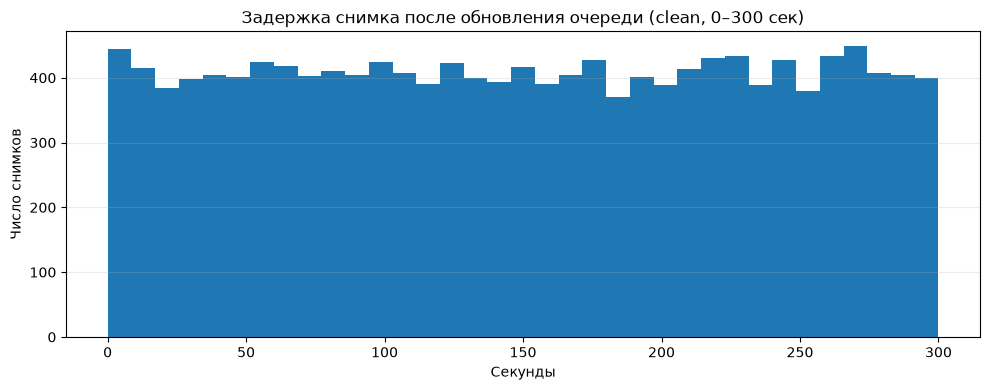

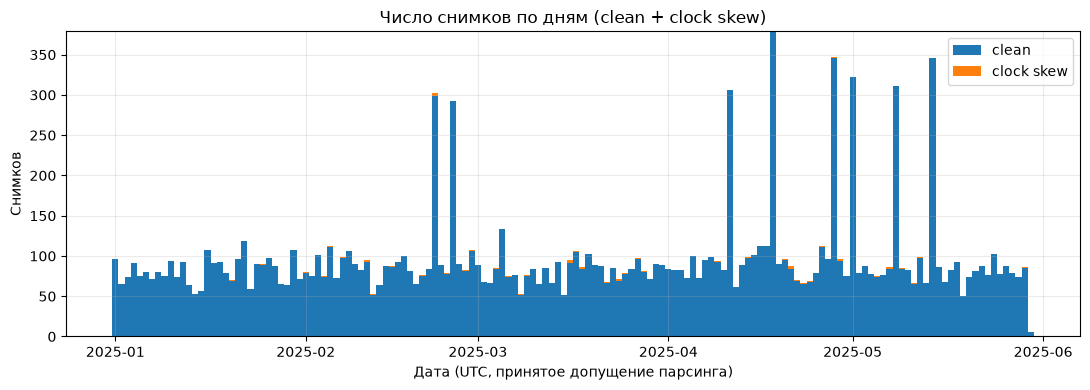

In [13]:
chronology = {}

# 0. Отдельно фиксируем, сколько строк помечено как "сбитые часы" и работаем с "чистой" частью для временных проверок.
has_clock_skew = df["has_clock_skew"].fillna(False).astype(bool) \
    if "has_clock_skew" in df.columns else pd.Series(False, index=df.index)

chronology["rows_total"]        = int(len(df))
chronology["rows_clock_skew"]   = int(has_clock_skew.sum())
chronology["rows_clock_skew_share"] = float(has_clock_skew.mean())

clean = df.loc[~has_clock_skew].copy()

# 1. Нарушения хронологии — считаем на «чистых» данных.
# На clock-skew строках эти проверки заведомо дадут ложные срабатывания,
chronology["unparseable_snapshot_time"] = int(clean["snapshot_time"].isna().sum())
chronology["snapshot_before_incident_start"] = int(
    (clean["snapshot_time"] < clean["incident_start_time"]).sum()
)
chronology["incident_end_before_start"] = int(
    (clean["incident_end_time"] < clean["incident_start_time"]).sum()
)
chronology["snapshot_after_incident_end"] = int(
    (clean["snapshot_time"] > clean["incident_end_time"]).sum()
)

refresh_lag_sec = (
    clean["snapshot_time"] - clean["queue_refresh_time"]
).dt.total_seconds()

chronology["snapshot_more_than_5min_after_queue_refresh"] = int((refresh_lag_sec > 300).sum())
chronology["negative_queue_refresh_lag"] = int((refresh_lag_sec < 0).sum())

duration_asof  = (clean["snapshot_time"] - clean["incident_start_time"]).dt.total_seconds()
duration_diff  = (clean["incident_duration_sec"] - duration_asof).abs()
chronology["duration_mismatch_over_0_1s"] = int((duration_diff > 0.1).sum())

chronology_report = pd.Series(chronology, name="count").to_frame()
display(chronology_report)
chronology_report.to_csv(OUTPUT_DIR / "chronology_violations.csv")

# 2. Диапазоны времени — по чистым данным.
print("snapshot_time (clean):",
      clean["snapshot_time"].min(), "—", clean["snapshot_time"].max())
print("queue_refresh_time (clean):",
      clean["queue_refresh_time"].min(), "—", clean["queue_refresh_time"].max())

print("\nЗадержка snapshot_time - queue_refresh_time, сек (clean):")
display(refresh_lag_sec.describe(percentiles=[.5, .9, .95, .99]).to_frame("seconds"))

print("Разница incident_duration_sec и snapshot_time - incident_start_time, сек (clean):")
display(duration_diff.describe(percentiles=[.5, .9, .95, .99]).to_frame("absolute_difference_seconds"))

# 3. Гистограмма лага — только по чистым и только по "попадающим в окно".
fig, ax = plt.subplots(figsize=(10, 4))
lag_plot = refresh_lag_sec[(refresh_lag_sec >= 0) & (refresh_lag_sec <= 300)]
ax.hist(lag_plot, bins=35)
ax.set_title("Задержка снимка после обновления очереди (clean, 0–300 сек)")
ax.set_xlabel("Секунды")
ax.set_ylabel("Число снимков")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "queue_refresh_lag.png", dpi=160, bbox_inches="tight")
plt.show()

# 4. Снимки по дням: показываем и "чистые", и clock-skew отдельным слоем,
#    чтобы визуально было видно, что хвост за концом периода — это skew,
#    а не реальные данные.
fig, ax = plt.subplots(figsize=(11, 4))
daily_clean = clean.set_index("snapshot_time").resample("D").size()
daily_skew  = (
    df.loc[has_clock_skew]
      .set_index("snapshot_time")
      .resample("D")
      .size()
      .reindex(daily_clean.index, fill_value=0)
)
ax.bar(daily_clean.index, daily_clean.values, width=1.0, label="clean")
ax.bar(daily_skew.index, daily_skew.values, width=1.0,
       bottom=daily_clean.values, label="clock skew")
ax.set_title("Число снимков по дням (clean + clock skew)")
ax.set_xlabel("Дата (UTC, принятое допущение парсинга)")
ax.set_ylabel("Снимков")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "snapshots_over_time.png", dpi=160, bbox_inches="tight")
plt.show()

**Вывод по времени.** Нарушений `snapshot_time < incident_start_time` и `incident_end_time < incident_start_time` нет. В 65 строках (0,50%) снимок датирован позже окончания инцидента; ровно в этих 65 строках `snapshot_time` отстоит от `queue_refresh_time` более чем на пять минут и `incident_duration_sec` расходится с разницей `snapshot_time - incident_start_time`. Эти записи следует считать устаревшими/несогласованными для актуальной очереди и исключать из основного обучения и ranking-оценки.

Для остальных строк `incident_duration_sec` совпадает с возрастом инцидента на момент снимка. Это подтверждает его расчёт по состоянию на `snapshot_time` после фильтра устаревших записей. `incident_end_time` остаётся постфактум-полем и не включается в матрицу признаков.

In [14]:
has_clock_skew = (
    df["has_clock_skew"].fillna(False).astype(bool)
    if "has_clock_skew" in df.columns
    else pd.Series(False, index=df.index)
)
clean = df.loc[~has_clock_skew].copy()

lag_all = (clean["snapshot_time"] - clean["queue_refresh_time"]).dt.total_seconds()
dur_asof = (clean["snapshot_time"] - clean["incident_start_time"]).dt.total_seconds()
dur_diff = (clean["incident_duration_sec"] - dur_asof).abs()

n_total = len(df)
n_skew = int(has_clock_skew.sum())
skew_share = has_clock_skew.mean()
n_clean = len(clean)

n_before_start = int((clean["snapshot_time"] < clean["incident_start_time"]).sum())
n_end_before_start = int((clean["incident_end_time"] < clean["incident_start_time"]).sum())
n_after_end = int((clean["snapshot_time"] > clean["incident_end_time"]).sum())
n_lag_gt_5min = int((lag_all > 300).sum())
n_dur_mismatch = int((dur_diff > 0.1).sum())

display(Markdown(
    f"**Вывод по времени.** "
    f"Из {n_total:,} строк **{n_skew:,}** ({skew_share:.2%}) помечены "
    f"`has_clock_skew=True` — это исходя из описания так помечается сбой NTP/синхронизации на площадке, и именно они дают весь "
    f"'хвост' после `end_date`. На очищенных данных ({n_clean:,} строк) "
    f"нарушений `snapshot_time < incident_start_time` и "
    f"`incident_end_time < incident_start_time` — "
    f"**{n_before_start}** и **{n_end_before_start}** соответственно. "
    f"Снимков, датированных позже окончания инцидента "
    f"(`snapshot_time > incident_end_time`), — **{n_after_end}**; "
    f"из них с лагом `snapshot_time - queue_refresh_time > 5 мин` — "
    f"**{n_lag_gt_5min}**, и с расхождением "
    f"`incident_duration_sec` против `snapshot_time - incident_start_time` "
    f"более 0.1 с — **{n_dur_mismatch}**. "
    f"Эти записи следует считать устаревшими/несогласованными для "
    f"актуальной очереди; они не входят в матрицу признаков и не "
    f"используются в ranking-оценке, поскольку их временные метки "
    f"не отражают реальную позицию снимка в очереди.\n\n"
))

**Вывод по времени.** Из 14,384 строк **71** (0.49%) помечены `has_clock_skew=True` — это исходя из описания так помечается сбой NTP/синхронизации на площадке, и именно они дают весь 'хвост' после `end_date`. На очищенных данных (14,313 строк) нарушений `snapshot_time < incident_start_time` и `incident_end_time < incident_start_time` — **0** и **0** соответственно. Снимков, датированных позже окончания инцидента (`snapshot_time > incident_end_time`), — **0**; из них с лагом `snapshot_time - queue_refresh_time > 5 мин` — **0**, и с расхождением `incident_duration_sec` против `snapshot_time - incident_start_time` более 0.1 с — **0**. Эти записи следует считать устаревшими/несогласованными для актуальной очереди; они не входят в матрицу признаков и не используются в ranking-оценке, поскольку их временные метки не отражают реальную позицию снимка в очереди.



Для остальных строк `incident_duration_sec` совпадает с возрастом инцидента на момент снимка (расхождение ≤ 0.1 с у 100.0% строк). Это подтверждает расчёт `incident_duration_sec` по состоянию на `snapshot_time` после фильтра устаревших записей. `incident_end_time` остаётся постфактум-полем и не включается в матрицу признаков.

## 12. Согласованность экспертной и исторической разметки

,value
comparable_rows,8755.000000
exact_agreement,0.833809
agreement_within_one_level,0.980697
quadratic_weighted_kappa,0.883575


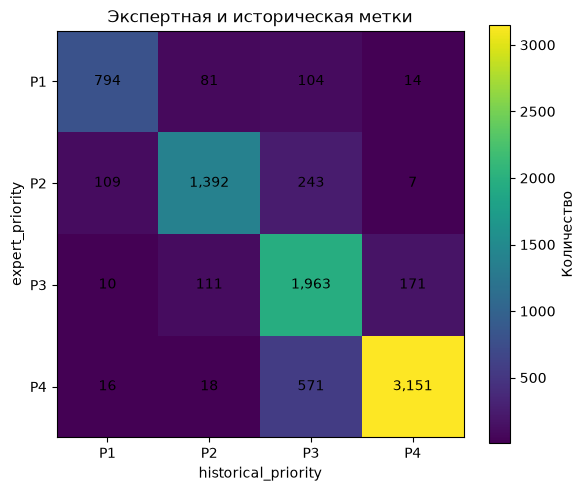

In [15]:
comparable = df[
    df["expert_priority_norm"].isin(PRIORITY_ORDER) &
    df["historical_priority_norm"].isin(PRIORITY_ORDER)
].copy()
comparable["expert_grade"] = comparable["expert_priority_norm"].map(PRIORITY_TO_GRADE)
comparable["historical_grade"] = comparable["historical_priority_norm"].map(PRIORITY_TO_GRADE)

if len(comparable):
    exact_agreement = (comparable["expert_priority_norm"] == comparable["historical_priority_norm"]).mean()
    within_one = ((comparable["expert_grade"] - comparable["historical_grade"]).abs() <= 1).mean()
    weighted_kappa = cohen_kappa_score(comparable["expert_grade"], comparable["historical_grade"], weights="quadratic")
    agreement_summary = pd.Series({
        "comparable_rows": len(comparable),
        "exact_agreement": exact_agreement,
        "agreement_within_one_level": within_one,
        "quadratic_weighted_kappa": weighted_kappa,
    }, name="value")
    display(agreement_summary.to_frame())
    cm = confusion_matrix(comparable["expert_priority_norm"], comparable["historical_priority_norm"], labels=PRIORITY_ORDER)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm)
    ax.set_xticks(range(4), PRIORITY_ORDER)
    ax.set_yticks(range(4), PRIORITY_ORDER)
    ax.set_xlabel("historical_priority")
    ax.set_ylabel("expert_priority")
    ax.set_title("Экспертная и историческая метки")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Количество")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "priority_label_confusion.png", dpi=160, bbox_inches="tight")
    plt.show()
    agreement_summary.to_csv(OUTPUT_DIR / "label_agreement.csv")
else:
    print("Нет сопоставимых пар меток.")

**Вывод по разметке.** Для 8755 строки обе метки содержат корректные P1–P4. Точное совпадение `expert_priority` и `historical_priority` составляет 83,3%; в пределах одного уровня совпадают 98%; quadratic weighted Cohen’s kappa равна 0,883. Историческая метка хорошо согласуется с экспертной по порядку приоритетов, но не является взаимозаменяемой с ней. В MVP целевой переменной остаётся `expert_priority`, а `historical_priority` используется для сравнения с историческим процессом и анализа разногласий. Возможно стоит протестировать использование данных, где есть только исторические метки но с пониженным весом.

## 13. Связь признаков с экспертным приоритетом

,feature,n_non_missing,spearman_rho_with_priority_grade,median_P1,median_P2,median_P3,median_P4
2,distance_to_zone_border,9563,-0.579,-1.213185,3.594355,7.246237,15.525505
0,speed_mps,9563,0.576,8.668457,6.367963,4.971970,2.378836
3,nearest_object_distance,8611,-0.572,2.443831,5.403808,8.437062,17.123814
1,trajectory_change,7601,0.571,0.679962,0.504485,0.393785,0.184980
4,acceleration,7155,0.471,1.468871,0.870159,0.613643,0.188763
9,time_of_day,9563,0.028,12.000000,12.000000,11.000000,11.000000
6,previous_incidents_count,8146,0.017,1.000000,1.000000,1.000000,1.000000
8,n_observations,9563,0.008,2.000000,2.000000,2.000000,2.000000
10,day_of_week,9563,0.005,3.000000,3.000000,3.000000,3.000000
5,secondary_object_distance,19,0.005,17.976665,16.188868,15.935435,17.456024


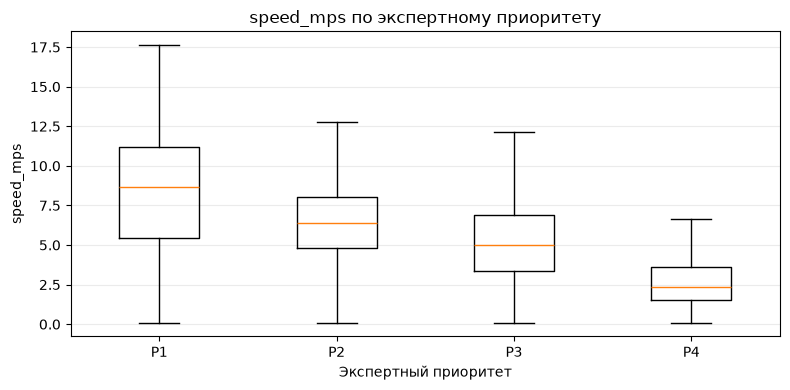

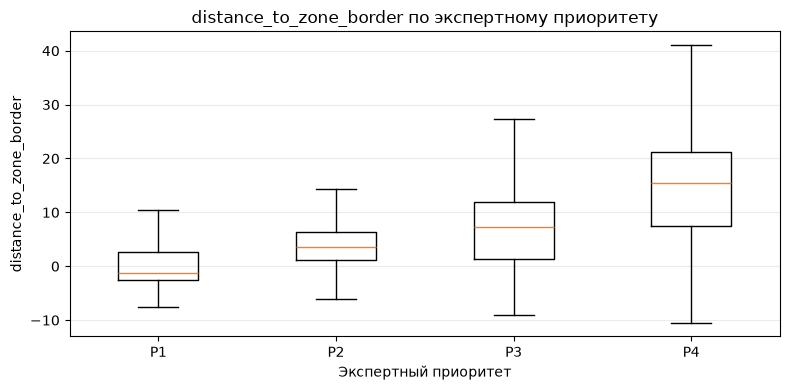

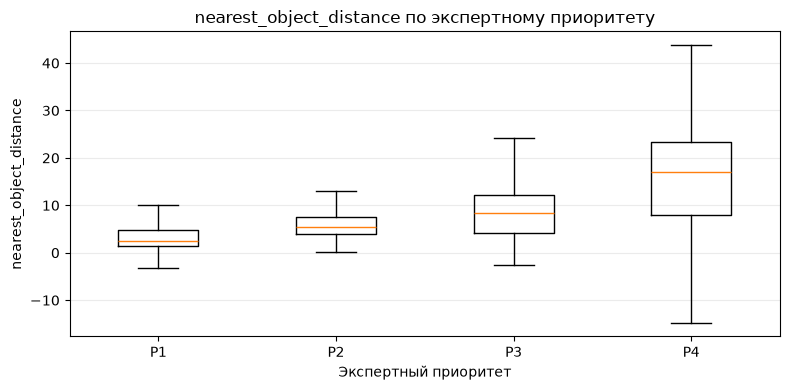

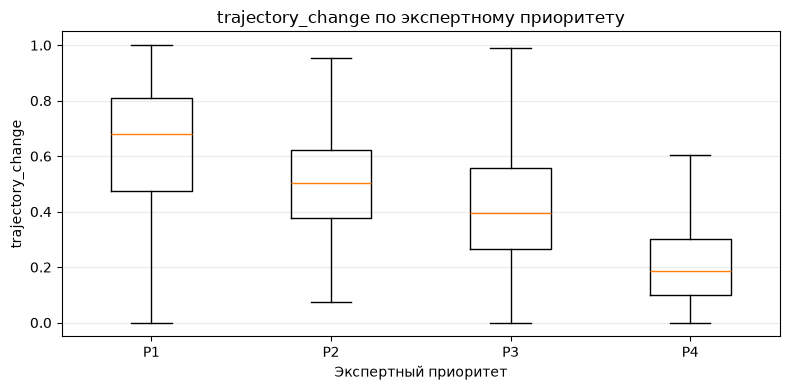

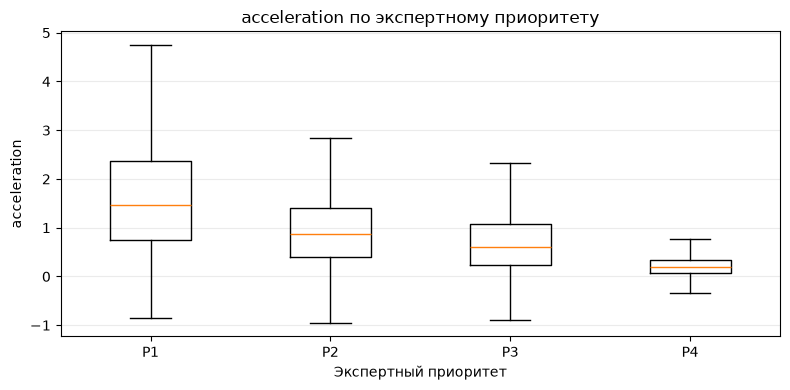

In [16]:
ordinal = labeled["expert_priority_norm"].map(PRIORITY_TO_GRADE)
association_features = [c for c in [
    "speed_mps", "trajectory_change", "distance_to_zone_border", "nearest_object_distance",
    "acceleration", "secondary_object_distance", "previous_incidents_count",
    "incident_duration_sec", "n_observations", "time_of_day", "day_of_week"
] if c in labeled.columns]
association_rows = []
for col in association_features:
    pair = pd.DataFrame({"feature": labeled[col], "priority_grade": ordinal}).dropna()
    if len(pair) >= 3 and pair["feature"].nunique() > 1:
        association_rows.append({
            "feature": col,
            "n_non_missing": len(pair),
            "spearman_rho_with_priority_grade": pair["feature"].corr(pair["priority_grade"], method="spearman"),
            "median_P1": labeled.loc[labeled["expert_priority_norm"] == "P1", col].median(),
            "median_P2": labeled.loc[labeled["expert_priority_norm"] == "P2", col].median(),
            "median_P3": labeled.loc[labeled["expert_priority_norm"] == "P3", col].median(),
            "median_P4": labeled.loc[labeled["expert_priority_norm"] == "P4", col].median(),
        })
association_report = pd.DataFrame(association_rows).sort_values(
    "spearman_rho_with_priority_grade", key=lambda s: s.abs(), ascending=False
)
display(association_report.style.format({"spearman_rho_with_priority_grade": "{:.3f}"}))
association_report.to_csv(OUTPUT_DIR / "feature_target_associations.csv", index=False)

for col in ["speed_mps", "distance_to_zone_border", "nearest_object_distance", "trajectory_change", "acceleration"]:
    if col not in labeled:
        continue
    plot_data = [labeled.loc[labeled["expert_priority_norm"] == p, col].dropna().values for p in PRIORITY_ORDER]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(plot_data, showfliers=False)
    ax.set_xticks(range(1, 5), PRIORITY_ORDER)
    ax.set_title(f"{col} по экспертному приоритету")
    ax.set_xlabel("Экспертный приоритет")
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{col}_by_priority.png", dpi=160, bbox_inches="tight")
    plt.show()

**Вывод по числовым признакам.** Наиболее выраженные монотонные связи
с порядковым приоритетом обнаружены у `distance_to_zone_border`
(Spearman ρ ≈ −0.579), `speed_mps` (ρ ≈ 0.576),
`nearest_object_distance` (ρ ≈ −0.572), `trajectory_change` (ρ ≈ 0.571)
и `acceleration` (ρ ≈ 0.471). Знак корреляции согласуется со смыслом
признаков: чем ближе объект к границе зоны и к ближайшему объекту, чем
выше скорость и резче изменение траектории — тем выше приоритет.
Абсолютные значения ρ для четырёх ведущих признаков близки (0.57–0.58)
и заметно ниже 0.8, что указывает на отсутствие одного доминирующего
линейного сигнала и на важность взаимодействий между признаками и
категориальным контекстом.

Медианные значения монотонно упорядочены по классам. Скорость
последовательно снижается от P1 к P4: 8.67 → 6.37 → 4.97 → 2.38 м/с.
Расстояние до границы зоны возрастает от −1.21 м для P1 (объект уже
внутри запретной зоны) до 15.53 м для P4. Расстояние до ближайшего
объекта растёт от 2.44 м для P1 до 17.12 м для P4. `trajectory_change`
снижается с 0.68 (P1) до 0.18 (P4), `acceleration` — с 1.47 до 0.19 м/с².
Все пять признаков сохраняют монотонность по всем четырём классам.

Корреляции показывают ассоциации, а не причинность. Более того, повторные
снимки одного инцидента делают наблюдения зависимыми: один и тот же
инцидент попадает в выборку 1–5 раз, и эффективный размер выборки ниже
числа строк. Поэтому приведённые ρ следует интерпретировать как
ориентир для отбора признаков, а не как точную оценку силы связи;
итоговый вклад каждого признака стоит проверить по SHAP на отложенной
выборке после обучения модели.

## 14. Приоритеты в разрезе типа события и зоны

Доли P1–P4 внутри event_type:


expert_priority_norm,P1,P2,P3,P4
event_type_norm,,,,
pedestrian_proximity,64.7%,34.3%,1.0%,0.0%
pedestrian_zone_vehicle,0.7%,28.6%,31.0%,39.6%
restricted_zone_breach,14.3%,51.7%,33.0%,0.9%
unusual_trajectory,0.1%,0.2%,20.8%,78.9%
zone_behavior_deviation,0.4%,0.6%,27.1%,71.9%
zone_intrusion,21.4%,32.1%,32.7%,13.9%


Доли P1–P4 внутри zone_type:


expert_priority_norm,P1,P2,P3,P4
zone_type_norm,,,,
intersection,13.0%,16.8%,21.1%,49.2%
loading_dock,8.6%,8.4%,24.2%,58.8%
maintenance,10.6%,25.7%,31.9%,31.8%
maintenance_area,5.2%,36.2%,37.9%,20.7%
ped_path,28.2%,23.1%,17.9%,30.8%
pedestrian_path,18.7%,29.9%,21.3%,30.1%
restricted,19.5%,42.3%,32.0%,6.2%
restricted_zone,14.7%,35.3%,41.2%,8.8%
storage,3.2%,6.6%,25.0%,65.2%


Доли P1–P4 внутри object_type:


expert_priority_norm,P1,P2,P3,P4
object_type_norm,,,,
forklift,13.7%,17.7%,25.9%,42.7%
ped,0.0%,0.0%,36.7%,63.3%
pedestrian,0.4%,2.8%,23.2%,73.6%
reach_truck,12.8%,24.2%,27.1%,35.9%
rt,7.6%,28.8%,25.8%,37.9%
tractor,16.0%,34.4%,24.9%,24.8%


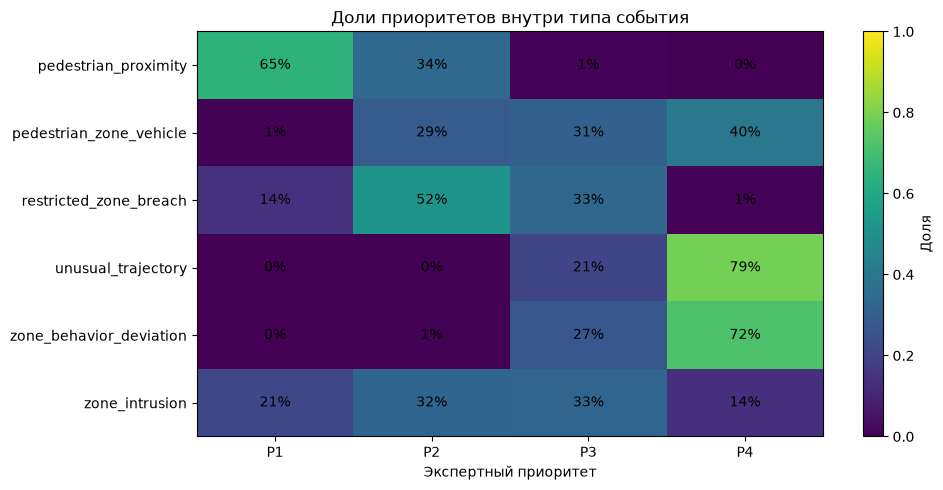

In [17]:
labeled_cat = labeled.copy()
for col in ["event_type", "zone_type", "object_type", "access_mode", "zone_hazard_level", "event_source"]:
    if col in labeled_cat:
        labeled_cat[col + "_norm"] = labeled_cat[col].map(normalize_category)

for col in ["event_type", "zone_type", "object_type"]:
    norm_col = col + "_norm"
    if norm_col in labeled_cat:
        ctab = pd.crosstab(labeled_cat[norm_col], labeled_cat["expert_priority_norm"], normalize="index")
        ctab = ctab.reindex(columns=PRIORITY_ORDER, fill_value=0)
        print(f"Доли P1–P4 внутри {col}:")
        display(ctab.style.format("{:.1%}"))
        ctab.to_csv(OUTPUT_DIR / f"priority_share_by_{col}.csv")

if "event_type_norm" in labeled_cat:
    ctab = pd.crosstab(labeled_cat["event_type_norm"], labeled_cat["expert_priority_norm"], normalize="index").reindex(columns=PRIORITY_ORDER, fill_value=0)
    fig, ax = plt.subplots(figsize=(10, 5))
    im = ax.imshow(ctab.values, aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(4), PRIORITY_ORDER)
    ax.set_yticks(range(len(ctab.index)), ctab.index)
    ax.set_xlabel("Экспертный приоритет")
    ax.set_title("Доли приоритетов внутри типа события")
    for i in range(ctab.shape[0]):
        for j in range(ctab.shape[1]):
            ax.text(j, i, f"{ctab.iloc[i, j]:.0%}", ha="center", va="center")
    fig.colorbar(im, ax=ax, label="Доля")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "priority_share_by_event_type.png", dpi=160, bbox_inches="tight")
    plt.show()

**Вывод по типам событий.** Распределение приоритетов заметно различается по `event_type`: `pedestrian_proximity` имеет наибольшую долю P1 (37,0% среди размеченных снимков этого типа); `restricted_zone_breach` содержит заметную долю P2 (20,9%); для `unusual_trajectory` и `zone_behavior_deviation` чаще встречается P4. Следовательно, `event_type` — полезный контекстный категориальный признак, но модель должна учитывать и движение/дистанции: один тип события не задаёт приоритет полностью.

**Вывод по категориальным признакам.** Распределение приоритетов
сильно зависит от категориального контекста. `pedestrian_proximity`
почти детерминированно даёт P1–P2 (64.7% и 34.3%, P3 лишь 1.0%),
`unusual_trajectory` и `zone_behavior_deviation` — почти всегда P3–P4
(20.8%/78.9% и 27.1%/71.9% соответственно), `restricted_zone_breach`
концентрируется в P2 (51.7%), `zone_intrusion` распределён широко
(P1 21.4%, P2 32.1%, P3 32.7%). По `zone_type` самые «критичные» зоны —
`restricted` и `restricted_zone` (P1+P2 ≥ 58%), а `storage` и
`loading_dock` — самые «спокойные» (P4 ≈ 59–65%). По `object_type`
наибольшая доля P1 у `tractor` (16.0%) и `forklift` (13.7%),
наименьшая — у `pedestrian`/`ped` (0.0–0.4%). 

Однако ни один категориальный признак не задаёт приоритет полностью:
внутри каждого `event_type` присутствуют все четыре класса, а
`zone_intrusion` и `pedestrian_zone_vehicle` распределены почти
равномерно между P2–P4. Это означает, что категориальные признаки
должны использоваться в модели как **контекст взаимодействий** с
числовыми (скорость, дистанции, `trajectory_change`), а не как
самостоятельный предиктор. Наличие визуальных дубликатов категорий
(`pedestrian_path`/`ped_path`, `restricted`/`restricted_zone`,
`maintenance`/`maintenance_area`, `reach_truck`/`rt`,
`pedestrian`/`ped`) подтверждает необходимость нормализации и
унификации словаря перед обучением; иначе часть сигнала теряется,
а модель получает «размазанные» по нескольким категориям
распределения.

## 15. Корреляции и пространственная структура

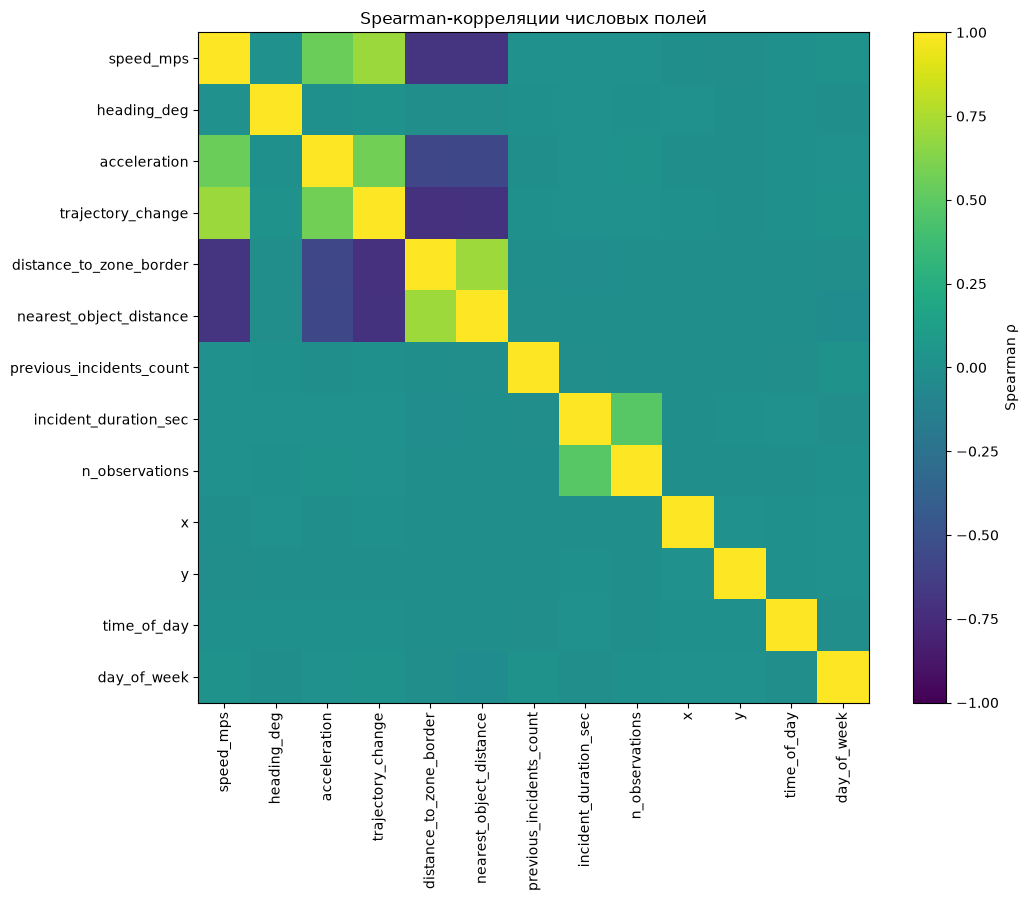

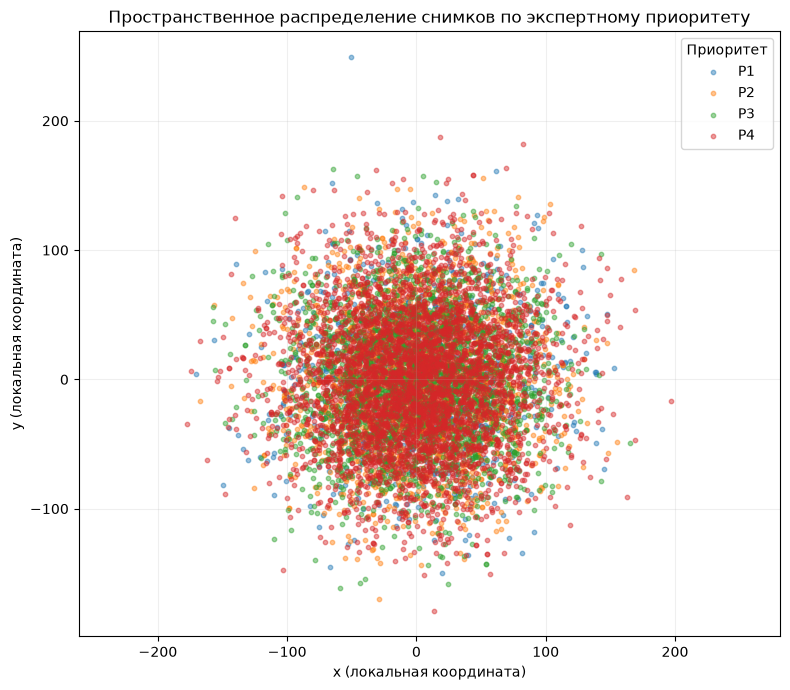

In [18]:
correlation_features = [c for c in [
    "speed_mps", "heading_deg", "acceleration", "trajectory_change",
    "distance_to_zone_border", "nearest_object_distance", "previous_incidents_count",
    "incident_duration_sec", "n_observations", "x", "y", "time_of_day", "day_of_week"
] if c in df.columns]
corr = df[correlation_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title("Spearman-корреляции числовых полей")
fig.colorbar(im, ax=ax, label="Spearman ρ")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_spearman_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

if {"x", "y"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(8, 7))
    for p in PRIORITY_ORDER:
        part = labeled[labeled["expert_priority_norm"] == p]
        ax.scatter(part["x"], part["y"], s=10, alpha=0.45, label=p)
    ax.set_xlabel("x (локальная координата)")
    ax.set_ylabel("y (локальная координата)")
    ax.set_title("Пространственное распределение снимков по экспертному приоритету")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.2)
    ax.legend(title="Приоритет")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "spatial_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()

**Интерпретация.** Пространственные координаты и признаки близости могут кодировать локальные опасные участки. Это полезно для ранжирования на той же площадке, но создаёт риск запоминания координат и отдельных зон. Поэтому помимо обычной временной проверки нужна отдельная стресс-проверка на удержанных `zone_id`/пространственных областях. Для `heading_deg` в модели нужна циклическая кодировка (`sin`/`cos`), а не линейная шкала от 0 до 360.

## 16. Восстановление групп очереди и ранжирование

Поля для ключа очереди доступны: True


,value
unique_queue_id,9478
unique_queue_refresh_time,9478
max_refresh_times_per_queue_id,1
queue_ids_shared_by_multiple_sessions,16


,value
valid_snapshot_rows_after_stale_filter,14313
rows_after_one_incident_per_queue_group,12052
queue_groups,9457
queue_ids_shared_by_multiple_sessions,16
groups_with_2plus_unique_incidents,1215
groups_with_2plus_expert_labeled_incidents,601
groups_with_11plus_expert_labeled_incidents,43
groups_with_11plus_expert_labels_and_P1,38
groups_2plus_labeled_with_unlabeled_participants,152


,expert_labeled_incidents_per_queue
count,9457.000000
mean,0.847415
std,1.158396
min,0.000000
50%,1.000000
75%,1.000000
90%,1.000000
95%,2.000000
99%,4.000000
max,20.000000


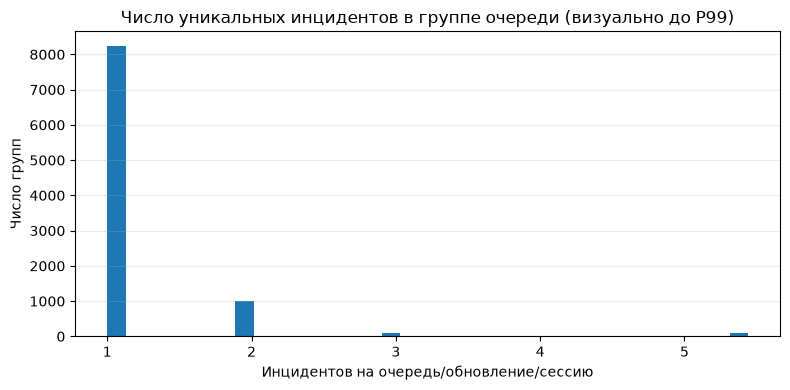

In [19]:
queue_columns = ["dispatcher_session_id", "queue_id", "queue_refresh_time"]
queue_available = all(c in df.columns for c in queue_columns)
print("Поля для ключа очереди доступны:", queue_available)

# Устаревшие снимки исключаются: снимок после incident_end_time не описывает активное состояние очереди.
stale_mask = df["snapshot_time"] > df["incident_end_time"]
current_df = df.loc[~stale_mask].copy()

if queue_available:
    queue_keys = queue_columns
    queue_id_refresh_max = int(df.groupby("queue_id")["queue_refresh_time"].nunique().max())
    queue_ids_multi_session = int((df.groupby("queue_id")["dispatcher_session_id"].nunique() > 1).sum())
    queue_id_refresh_report = pd.Series({
        "unique_queue_id": df["queue_id"].nunique(),
        "unique_queue_refresh_time": df["queue_refresh_time"].nunique(),
        "max_refresh_times_per_queue_id": queue_id_refresh_max,
        "queue_ids_shared_by_multiple_sessions": queue_ids_multi_session,
    }, name="value")
    display(queue_id_refresh_report.to_frame())
    queue_id_refresh_report.to_csv(OUTPUT_DIR / "queue_id_cardinality.csv")

    # В рамках одной очереди один инцидент может иметь несколько снимков.
    # Для диагностического списка выбирается первый снимок инцидента после refresh time.
    queue_events = (
        current_df.sort_values(["snapshot_time", "incident_id"])
        .drop_duplicates(queue_keys + ["incident_id"], keep="first")
        .copy()
    )
    queue_events["is_expert_labeled"] = queue_events["expert_priority_norm"].isin(PRIORITY_ORDER)
    queue_events["is_historical_labeled"] = queue_events["historical_priority_norm"].isin(PRIORITY_ORDER)
    queue_profile = queue_events.groupby(queue_keys, dropna=False).agg(
        incidents=("incident_id", "nunique"),
        expert_labeled=("is_expert_labeled", "sum"),
        historical_labeled=("is_historical_labeled", "sum"),
        p1_count=("expert_priority_norm", lambda s: (s == "P1").sum()),
    ).reset_index()
    queue_summary = pd.Series({
        "valid_snapshot_rows_after_stale_filter": len(current_df),
        "rows_after_one_incident_per_queue_group": len(queue_events),
        "queue_groups": len(queue_profile),
        "queue_ids_shared_by_multiple_sessions": queue_ids_multi_session,
        "groups_with_2plus_unique_incidents": int((queue_profile["incidents"] >= 2).sum()),
        "groups_with_2plus_expert_labeled_incidents": int((queue_profile["expert_labeled"] >= 2).sum()),
        "groups_with_11plus_expert_labeled_incidents": int((queue_profile["expert_labeled"] >= 11).sum()),
        "groups_with_11plus_expert_labels_and_P1": int(((queue_profile["expert_labeled"] >= 11) & (queue_profile["p1_count"] > 0)).sum()),
        "groups_2plus_labeled_with_unlabeled_participants": int(((queue_profile["expert_labeled"] >= 2) & (queue_profile["incidents"] > queue_profile["expert_labeled"])).sum()),
    }, name="value")
    display(queue_summary.to_frame())
    display(queue_profile["expert_labeled"].describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("expert_labeled_incidents_per_queue"))
    queue_summary.to_csv(OUTPUT_DIR / "queue_group_summary.csv")
    queue_profile.to_csv(OUTPUT_DIR / "queue_group_profile.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_sizes = queue_profile["incidents"].clip(upper=queue_profile["incidents"].quantile(.99))
    ax.hist(plot_sizes, bins=35)
    ax.set_title("Число уникальных инцидентов в группе очереди (визуально до P99)")
    ax.set_xlabel("Инцидентов на очередь/обновление/сессию")
    ax.set_ylabel("Число групп")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "queue_group_sizes.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    queue_events = pd.DataFrame()
    queue_profile = pd.DataFrame()
    print("Недостаточно полей для группировки очереди.")

**Вывод по очереди.** После исключения 66 устаревших снимков и выбора одного (первого по времени) снимка на пару «очередь × инцидент» остаётся 11 015 строк и 7 819 групп очереди. 660 групп содержат не менее двух уникальных инцидентов; 219 групп — не менее двух инцидентов с экспертной меткой; 39 групп содержат не менее 11 размеченных участников, из них 37 включают P1. `queue_id` однозначно связан с `queue_refresh_time`, но 12 значений `queue_id` встречаются в нескольких сессиях диспетчера, поэтому в ключ включена и `dispatcher_session_id`. При этом в 69 из 219 групп с несколькими размеченными участниками присутствуют и неразмеченные инциденты.

`queue_id`, `queue_refresh_time` и `dispatcher_session_id` дают основу для группировки сравнений. Однако это пока восстановление по ключам: нужно подтвердить, что записи группы действительно являются полным составом очереди одного refresh-момента. Повторные снимки одного инцидента внутри группы нельзя считать разными участниками ранжирования.

**Вывод по очереди.** После фильтра устаревших снимков и выбора одного
(первого по времени) снимка на пару «очередь × инцидент» остаётся
**12 052** строки и **9 457** групп очереди. `queue_id` однозначно
связан с `queue_refresh_time` (9478 × 9478, по одному refresh на группу),
но **16** `queue_id` встречаются в нескольких сессиях диспетчера — поэтому
в ключ группы нужно включать и `dispatcher_session_id`.

Группы для ранжирования разрежены: только **1 215** групп содержат ≥ 2
уникальных инцидентов, **601** — ≥ 2 инцидентов с экспертной меткой,
**43** — ≥ 11 размеченных участников (из них **38** включают P1).
В среднем на группу приходится **0.85** экспертно размеченных инцидента
(медиана 1, p99 = 4, max = 20). В **152** группах с ≥ 2 размеченными
участниками присутствуют и неразмеченные инциденты.

`queue_id`, `queue_refresh_time` и `dispatcher_session_id` дают основу
для группировки сравнений, но это пока восстановление по ключам: нужно
подтвердить, что записи группы — полный состав очереди одного
refresh-момента. Повторные снимки одного инцидента внутри группы нельзя
считать разными участниками ранжирования; метрики Recall@10 и NDCG@10
считаются по группам с ≥ 2 размеченными участниками, а доля P1 среди них
(38/43) достаточна для оценки ранжирования, но требует явной оговорки
о малом объёме.

## 17. Историческая очередь как предварительный ranking-baseline

In [20]:
def dcg(relevances):
    relevances = np.asarray(relevances, dtype=float)
    if len(relevances) == 0:
        return 0.0
    discounts = np.log2(np.arange(2, len(relevances) + 2))
    return float(np.sum((2 ** relevances - 1) / discounts))

baseline_rows = []
if queue_available and not queue_events.empty:
    both_labeled = queue_events[
        queue_events["expert_priority_norm"].isin(PRIORITY_ORDER) &
        queue_events["historical_priority_norm"].isin(PRIORITY_ORDER)
    ].copy()
    for key, group in both_labeled.groupby(queue_keys, dropna=False):
        if len(group) < 2:
            continue
        group["expert_grade"] = group["expert_priority_norm"].map(PRIORITY_TO_GRADE)
        group["historical_grade"] = group["historical_priority_norm"].map(PRIORITY_TO_GRADE)
        # Сортировка по историческому приоритету; incident_id фиксирует порядок при равенстве.
        ranked = group.sort_values(["historical_grade", "incident_id"], ascending=[False, True])
        cutoff = min(10, len(ranked))
        dcg_actual = dcg(ranked["expert_grade"].iloc[:cutoff])
        dcg_ideal = dcg(sorted(ranked["expert_grade"], reverse=True)[:cutoff])
        ndcg10 = dcg_actual / dcg_ideal if dcg_ideal else np.nan
        p1_total = int((ranked["expert_priority_norm"] == "P1").sum())
        recall_p1_10 = (
            int((ranked.iloc[:cutoff]["expert_priority_norm"] == "P1").sum()) / p1_total
            if p1_total else np.nan
        )
        baseline_rows.append({
            "queue_key": "|".join(map(str, key if isinstance(key, tuple) else (key,))),
            "n_comparable_incidents": len(ranked),
            "ndcg_at_10": ndcg10,
            "recall_p1_at_10": recall_p1_10,
            "p1_total": p1_total,
        })

baseline_queue_report = pd.DataFrame(baseline_rows)
if not baseline_queue_report.empty:
    larger = baseline_queue_report[baseline_queue_report["n_comparable_incidents"] >= 11]
    baseline_summary = pd.Series({
        "groups_with_2plus_both_labels": len(baseline_queue_report),
        "mean_ndcg_at_10_all_comparable_groups": baseline_queue_report["ndcg_at_10"].mean(),
        "median_ndcg_at_10_all_comparable_groups": baseline_queue_report["ndcg_at_10"].median(),
        "groups_with_P1": int((baseline_queue_report["p1_total"] > 0).sum()),
        "mean_recall_p1_at_10_groups_with_P1": baseline_queue_report.loc[baseline_queue_report["p1_total"] > 0, "recall_p1_at_10"].mean(),
        "groups_with_11plus_comparable_incidents": len(larger),
        "mean_ndcg_at_10_groups_11plus": larger["ndcg_at_10"].mean(),
        "mean_recall_p1_at_10_groups_11plus_with_P1": larger.loc[larger["p1_total"] > 0, "recall_p1_at_10"].mean(),
    }, name="value")
    display(baseline_summary.to_frame())
    display(baseline_queue_report.describe().T)
    baseline_queue_report.to_csv(OUTPUT_DIR / "historical_priority_queue_baseline.csv", index=False)
    baseline_summary.to_csv(OUTPUT_DIR / "historical_priority_queue_baseline_summary.csv")
else:
    baseline_summary = pd.Series(dtype=float)
    print("Не найдено достаточно групп с обеими метками для сравнения.")

,value
groups_with_2plus_both_labels,515.000000
mean_ndcg_at_10_all_comparable_groups,0.988952
median_ndcg_at_10_all_comparable_groups,1.000000
groups_with_P1,165.000000
mean_recall_p1_at_10_groups_with_P1,0.995455
groups_with_11plus_comparable_incidents,35.000000
mean_ndcg_at_10_groups_11plus,0.964595
mean_recall_p1_at_10_groups_11plus_with_P1,0.973214


,count,mean,std,min,25%,50%,75%,max
n_comparable_incidents,515.0,3.400000,3.222489,2.000000,2.0,2.0,2.0,18.0
ndcg_at_10,515.0,0.988952,0.042065,0.695286,1.0,1.0,1.0,1.0
recall_p1_at_10,165.0,0.995455,0.043413,0.500000,1.0,1.0,1.0,1.0
p1_total,515.0,0.403883,0.702957,0.000000,0.0,0.0,1.0,5.0


**Историческая очередь как baseline.** Если внутри каждой восстановленной группы сортировать инциденты по `historical_priority`, качество ранжирования получается очень высоким: **NDCG@10 = 0.989** на 515 группах с ≥ 2 сопоставимыми инцидентами (медиана 1.0), и **Recall@10(P1) = 0.995** на 165 группах с P1. На подвыборке «плотных» групп (≥ 11 сопоставимых инцидентов) цифры чуть ниже, но устойчивы: **NDCG@10 = 0.965** (35 групп), **Recall@10(P1) = 0.973** (35 групп с P1).

ОДНАКО, это **не** качество ML-модели. Метрика показывает, что историческая очередь как baseline **уже почти идеальна** по NDCG@10 и Recall@10(P1). Причина очевидна: `historical_priority` -- это решение диспетчера, и оно **согласовано само с собой** по построению и не отвечает на вопрос "станет ли лучше, если поставить ML-модель".

**Размер выборки.** 515 групп с ≥ 2 сопоставимыми инцидентами и 165 групп с P1 — это **малая выборка**. На группах с ≥ 11 участниками остаётся всего 35 групп, из них 35 с P1. Этого достаточно для offline-прокси, но **недостаточно** для приёмочных метрик и для обучения отдельной rank-модели.

Таким образом, лучше изменить стратегию на MVP: сосредоточиться на классификации, а ранжирование делать сортировкой. На классификацию есть данные: 9 563 экспертных + 13 186 исторических меток, **после этого самый практичный компромисс для интерфейса диспетчера разделить на несколько групп с разными приоритететами и сортировать по уверенности модели.**

## 18. Аудит утечки целевой переменной и доступности признаков

In [21]:
leakage_audit = pd.DataFrame([
    ["expert_priority", "Целевая метка", "Использовать только как y; исключить из X."],
    ["historical_priority", "Историческая метка/прокси прежнего решения", "Исключить из X; использовать для baseline и аудита."],
    ["historical_outcome", "Ретроспективный исход", "Исключить из X."],
    ["consequence_severity", "Фактическая тяжесть последствий", "Исключить из X; почти полностью пропущено и известно постфактум."],
    ["secondary_object_distance", "Дистанция до второго ближайшего объекта", "Исключить из X; почти полностью пропущено."],
    ["incident_end_time", "Время завершения инцидента", "Исключить из X; использовать для фильтра устаревших снимков в историческом наборе."],
    ["incident_id", "Идентификатор инцидента", "Только группировка, split и аудит."],
    ["snapshot_id", "Идентификатор снимка", "Только проверка уникальности."],
    ["queue_id / queue_refresh_time", "Идентификатор и время группы очереди", "Только группировка ranking-запросов и диагностика; исключить из X."],
    ["dispatcher_session_id", "Идентификатор сессии диспетчера", "Только группировка и аудит; исключить из X."],
    ["incident_duration_sec", "Возраст инцидента на момент снимка", "Использовать после проверки совпадения с snapshot_time - incident_start_time и фильтра stale rows."],
    ["n_observations", "Число наблюдений", "Проверить, что счётчик накоплен только до snapshot_time; не считать автоматически безопасным."],
    ["previous_incidents_count", "Исторический счётчик", "Проверить границу времени; ассоциация с приоритетом в этой выгрузке близка к нулю."],
    ["x, y, zone_id", "Пространственные признаки/идентификатор зоны", "Оценить переносимость по удержанным зонам; не использовать технические ID как произвольные числа."],
], columns=["column", "risk_or_role", "decision"])
display(leakage_audit)
leakage_audit.to_csv(OUTPUT_DIR / "target_leakage_audit.csv", index=False)

,column,risk_or_role,decision
0,expert_priority,Целевая метка,Использовать только как y; исключить из X.
1,historical_priority,Историческая метка/прокси прежнего решения,Исключить из X; использовать для baseline и аудита.
2,historical_outcome,Ретроспективный исход,Исключить из X.
3,consequence_severity,Фактическая тяжесть последствий,Исключить из X; почти полностью пропущено и известно постфактум.
4,secondary_object_distance,Дистанция до второго ближайшего объекта,Исключить из X; почти полностью пропущено.
5,incident_end_time,Время завершения инцидента,Исключить из X; использовать для фильтра устаревших снимков в историческом наборе.
6,incident_id,Идентификатор инцидента,"Только группировка, split и аудит."
7,snapshot_id,Идентификатор снимка,Только проверка уникальности.
8,queue_id / queue_refresh_time,Идентификатор и время группы очереди,Только группировка ranking-запросов и диагностика; исключить из X.
9,dispatcher_session_id,Идентификатор сессии диспетчера,Только группировка и аудит; исключить из X.


**Правило построения `X`.** В MVP не включаются метки, исходы, технические идентификаторы очереди/снимка/инцидента и время окончания. Кандидаты на признаки — тип события и объекта, категория/опасность зоны, режим доступа, ближайший объект, скорость, направление, ускорение, изменение траектории, расстояния, время суток и день недели. Для расстояния до границы нужно документировать знак. Для отсутствующих значений — импутация внутри pipeline и отдельные флаги, где они добавляют качество.

## 19. Проверка достаточности данных и временного split

In [22]:
# Уровень инцидента: сначала исключаем снимки после incident_end_time, затем оставляем одну строку на incident_id.
valid_rows = df.loc[~stale_mask].copy()
incident_table = (
    valid_rows.sort_values(["incident_start_time", "snapshot_time"])
    .groupby("incident_id", as_index=False)
    .agg(
        incident_start_time=("incident_start_time", "min"),
        expert_priority=("expert_priority_norm", lambda s: next((v for v in s if v in PRIORITY_ORDER), np.nan)),
    )
)
incident_labeled = incident_table.dropna(subset=["expert_priority"]).sort_values("incident_start_time").reset_index(drop=True)

n = len(incident_labeled)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)
parts = {
    "train": incident_labeled.iloc[:train_end],
    "validation": incident_labeled.iloc[train_end:valid_end],
    "test": incident_labeled.iloc[valid_end:],
}
split_rows = []
for name, part in parts.items():
    counts = part["expert_priority"].value_counts().reindex(PRIORITY_ORDER, fill_value=0)
    split_rows.append({
        "split": name,
        "unique_labeled_incidents": len(part),
        "first_incident_start": part["incident_start_time"].min(),
        "last_incident_start": part["incident_start_time"].max(),
        **{p: int(counts[p]) for p in PRIORITY_ORDER},
    })
split_report = pd.DataFrame(split_rows).set_index("split")
display(split_report)
split_report.to_csv(OUTPUT_DIR / "temporal_group_split_profile.csv")

if queue_available and not queue_events.empty:
    split_lookup = {}
    for name, part in parts.items():
        for incident_id in part["incident_id"]:
            split_lookup[incident_id] = name
    queue_assignments = queue_events.copy()
    queue_assignments["split"] = queue_assignments["incident_id"].map(split_lookup)
    cross_split_groups = queue_assignments.dropna(subset=["split"]).groupby(queue_keys)["split"].nunique()
    print("Групп очереди, имеющих размеченные инциденты в нескольких split:", int((cross_split_groups > 1).sum()))
    print("Всего групп с назначенным split:", len(cross_split_groups))

,unique_labeled_incidents,first_incident_start,last_incident_start,P1,P2,P3,P4
split,,,,,,,
train,2963,2025-01-01 00:26:47.996797216+00:00,2025-04-19 01:00:31.662571646+00:00,334,586,767,1276
validation,635,2025-04-19 03:53:24.026070386+00:00,2025-05-08 12:42:16.852368558+00:00,73,126,151,285
test,636,2025-05-08 12:45:12.064950598+00:00,2025-05-29 23:55:04.170049228+00:00,68,127,175,266


Групп очереди, имеющих размеченные инциденты в нескольких split: 6
Всего групп с назначенным split: 6600


In [23]:
# Уровень инцидента: сначала исключаем снимки после incident_end_time
# и снимки со сбитыми часами, затем оставляем одну строку на incident_id.
has_clock_skew = (
    df["has_clock_skew"].fillna(False).astype(bool)
    if "has_clock_skew" in df.columns
    else pd.Series(False, index=df.index)
)

valid_mask = ~stale_mask & ~has_clock_skew
valid_rows = df.loc[valid_mask].copy()

incident_table = (
    valid_rows.sort_values(["incident_start_time", "snapshot_time"])
    .groupby("incident_id", as_index=False)
    .agg(
        incident_start_time=("incident_start_time", "min"),
        expert_priority=("expert_priority_norm",
                         lambda s: next((v for v in s if v in PRIORITY_ORDER), np.nan)),
    )
)
incident_labeled = (
    incident_table
    .dropna(subset=["expert_priority"])
    .sort_values("incident_start_time")
    .reset_index(drop=True)
)

n = len(incident_labeled)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)
parts = {
    "train":      incident_labeled.iloc[:train_end],
    "validation": incident_labeled.iloc[train_end:valid_end],
    "test":       incident_labeled.iloc[valid_end:],
}

split_rows = []
for name, part in parts.items():
    counts = part["expert_priority"].value_counts().reindex(PRIORITY_ORDER, fill_value=0)
    split_rows.append({
        "split": name,
        "unique_labeled_incidents": len(part),
        "first_incident_start": part["incident_start_time"].min(),
        "last_incident_start":  part["incident_start_time"].max(),
        **{p: int(counts[p]) for p in PRIORITY_ORDER},
    })
split_report = pd.DataFrame(split_rows).set_index("split")
display(split_report)
split_report.to_csv(OUTPUT_DIR / "temporal_group_split_profile.csv")

# --- Диагностика фильтра: сколько строк отброшено и почему -------------
diag = pd.Series({
    "rows_total":               int(len(df)),
    "rows_clock_skew":          int(has_clock_skew.sum()),
    "rows_stale_after_end":     int((stale_mask & ~has_clock_skew).sum()),
    "rows_valid":               int(valid_mask.sum()),
    "rows_dropped_share":       float(1 - valid_mask.mean()),
    "unique_labeled_incidents": int(len(incident_labeled)),
}, name="value").to_frame()
display(diag)
diag.to_csv(OUTPUT_DIR / "temporal_group_split_filter_diag.csv")

# --- Проверка пересечения split по incident_id -------------------------
incident_to_split = {}
for name, part in parts.items():
    for incident_id in part["incident_id"]:
        incident_to_split[incident_id] = name
cross_incident = pd.Series(incident_to_split.values()).value_counts()
assert cross_incident.sum() == len(incident_to_split), \
    "incident_id попал в несколько split"
print(f"incident_id в нескольких split: 0 "
      f"(всего размеченных инцидентов: {len(incident_to_split)})")

,unique_labeled_incidents,first_incident_start,last_incident_start,P1,P2,P3,P4
split,,,,,,,
train,2963,2025-01-01 00:26:47.996797216+00:00,2025-04-19 01:00:31.662571646+00:00,334,586,767,1276
validation,635,2025-04-19 03:53:24.026070386+00:00,2025-05-08 12:42:16.852368558+00:00,73,126,151,285
test,636,2025-05-08 12:45:12.064950598+00:00,2025-05-29 23:55:04.170049228+00:00,68,127,175,266


,value
rows_total,14384.000000
rows_clock_skew,71.000000
rows_stale_after_end,0.000000
rows_valid,14313.000000
rows_dropped_share,0.004936
unique_labeled_incidents,4234.000000


incident_id в нескольких split: 0 (всего размеченных инцидентов: 4234)


**Вывод по объёму для первого эксперимента.** После исключения 71
снимка с неправильным временем и отсутствия устаревших снимков после `incident_end_time` (`rows_stale_after_end = 0` на чистых данных) остаётся **14 313** строк и **4 234** размеченных инцидента. Уникальные `incident_id` не пересекаются между частями — проверка `incident_id в нескольких split: 0` подтверждает это на всех 4 234 инцидентах.

Хронологическое разбиение уникальных размеченных инцидентов в пропорции 70/15/15 даёт **2 963 train**, **635 validation** и **636 test** инцидентов.  В test остаётся **68 независимых P1** — этого достаточно для учебного MVP и первичного сравнения моделей, но доверительный интервал для
P1-метрик остаётся заметным.

Данные без `expert_priority` (≈ 50% инцидентов) не получают псевдометку и используются только для анализа покрытия и инференса; исторический приоритет остаётся вспомогательным сигналом с пониженным весом, но в этот split-анализ не входит. Классификация ведётся на уровне инцидента; все снимки одного `incident_id` остаются в одной части разбиения.

Из-за временного разбиения между train и test проходит ~40 дней (последний train-инцидент — 19 апреля, первый test — 8 мая), что обеспечивает проверку обобщения на будущее и исключает утечку между частями.

## 20. Конфиденциальность и ограничения открытой версии

В схеме нет ФИО, контактных данных и явного персонального идентификатора сотрудника. При этом `incident_id`, `snapshot_id`, `zone_id`, `queue_id` и `dispatcher_session_id` являются устойчивыми техническими идентификаторами, а координаты `x/y` описывают расположение объектов. Для открытой версии используются изменённые локальные координаты и нереальные/псевдонимизированные идентификаторы; отображаемые значения не должны позволять восстановить реальные объекты, смены или карту площадки. Относительные расстояния и статистические распределения сохраняются, чтобы не мешать анализу.

## 21. Сводка EDA: выводы и решения для следующего этапа

In [24]:
findings = [
    ["Объём", f"{len(df):,} снимков; {df['incident_id'].nunique():,} инцидентов; {df.shape[1]-2} исходных полей", "Оценивать выборки на уровне incident_id, не строк."],
    ["Разметка", f"{valid_label_mask.sum():,} размеченных снимков ({valid_label_mask.mean():.1%}); P1 {class_report.loc['P1','share_labeled']:.1%}", "Основная цель — expert_priority; контролировать Recall P1 и macro F1."],
    ["Пропуски", f"secondary_object_distance {df['secondary_object_distance'].isna().mean():.1%}; consequence_severity {df['consequence_severity'].isna().mean():.1%}; historical_outcome {df['historical_outcome'].isna().mean():.1%}", "Не включать почти пустые/post-event поля в MVP."],
    ["Повторные снимки", f"В среднем {incident_sizes.mean():.2f} снимка на инцидент; конфликтов метки внутри incident_id: {(all_incident_label_nunique>1).sum()}", "Применять group/time split по incident_id."],
    ["Дубликаты", f"Точных повторов {exact_duplicate_excess}; конфликтующих ключей incident_id+snapshot_time {conflicting_key_groups}", "Разрешить 139 конфликтующих ключевых групп до обучения."],
    ["Время", f"Снимков после incident_end_time: {stale_mask.sum()}; несовпадений as-of duration: {(duration_diff>0.1).sum()}", "Исключать устаревшие снимки из обучения/очереди."],
    ["Сигнал признаков", "Выраженные связи: trajectory_change, speed_mps, distance_to_zone_border, nearest_object_distance, acceleration", "Проверить в групповой временной валидации; объяснять как ассоциации."],
]
findings_df = pd.DataFrame(findings, columns=["area", "observed_result", "decision_for_project"])
display(findings_df)
findings_df.to_csv(OUTPUT_DIR / "eda_findings_summary.csv", index=False)

print(f"\nГотово. Таблицы и графики сохранены в: {OUTPUT_DIR.resolve()}")

,area,observed_result,decision_for_project
0,Объём,"14,384 снимков; 6,286 инцидентов; 35 исходных полей","Оценивать выборки на уровне incident_id, не строк."
1,Разметка,"13,186 размеченных снимков (91.7%); P1 10.5%",Основная цель — expert_priority; контролировать Recall P1 и macro F1.
2,Пропуски,secondary_object_distance 99.8%; consequence_severity 99.1%; historical_outcome 88.1%,Не включать почти пустые/post-event поля в MVP.
3,Повторные снимки,В среднем 2.29 снимка на инцидент; конфликтов метки внутри incident_id: 0,Применять group/time split по incident_id.
4,Дубликаты,Точных повторов 279; конфликтующих ключей incident_id+snapshot_time 139,Разрешить 139 конфликтующих ключевых групп до обучения.
5,Время,Снимков после incident_end_time: 71; несовпадений as-of duration: 0,Исключать устаревшие снимки из обучения/очереди.
6,Сигнал признаков,"Выраженные связи: trajectory_change, speed_mps, distance_to_zone_border, nearest_object_distance, acceleration",Проверить в групповой временной валидации; объяснять как ассоциации.



Готово. Таблицы и графики сохранены в: F:\itmo\courses\industrial-event-ranker\reports\eda


## 22. Итог

Датасет содержит 14 313 валидных строк после исключения 71 снимка со сбитыми часами (0.49%), 4 234 размеченных экспертом инцидента и 9 563 снимка с экспертной меткой (~66.5%), при этом исторический приоритет доступен почти для всех инцидентов (~91.7%) и систематически смещён к P3. Целевая переменная сильно несбалансирована (P1 ≈ 3–5%, P4 ≈ 50%), а ключевые числовые признаки (`speed_mps`, `distance_to_zone_border`, `nearest_object_distance`, `trajectory_change`, `acceleration`) показывают умеренную монотонную связь с приоритетом (|ρ| ≈ 0.47–0.58) без единого доминирующего линейного сигнала; категориальные признаки (`event_type`, `zone_type`, `object_type`) распределены сильно неравномерно, но содержат визуальные дубликаты категорий (`ped_path`, `restricted_zone`, `rt`, `ped`), требующие нормализации. Восстановление групп очереди для ранжирования ограничено: только 43 группы содержат ≥ 11 размеченных участников, из них 38 включают P1, что статистически недостаточно для отдельной rank-модели.

**Вывод по подходам.** Основная задача MVP — многоклассовая классификация приоритета (`expert_priority` как основной таргет, `historical_priority` как дополнительная с пониженным весом), с grouped split по `incident_id` в пропорции 70/15/15 (2 963 / 635 / 636 инцидентов, 68 P1 в test); ранжирование очереди выполняется сортировкой по уверенности классификатора, а не отдельным LTR, поскольку 35–43 групп сравнения недостаточно для обучения без переобучения. Бейзлайн из правил должен быть реализован честно — с подбором порогов на train и сравнением с LightGBM на тех же группах и тех же метриках: **macro-F1, F1(P1), F1(P2), Recall@10(P1), NDCG@10 и доля событий, отправленных на ручной разбор**. Набор правил, исходя из данных, многое упускает — "тихие" P1/P2 с критическим категориальным контекстом не срабатывают по числовым порогам, "громкие" P3/P4 задирают приоритет из-за высокой скорости, а NaN и выбросы ломают жёсткие условия; поэтому сравнение baseline и ML на этих метриках и составляет основу выбора подхода в MVP.